# Clasificación de Sonidos de la Naturaleza usando el Audio Spectrogram Transformer (AST)
## Técnicas de Deep Learning - MiniProyecto 4

Presentado por:

- Rafael Albarracín: **r.albarracin@uniandes.edu.co**
- Jhon Hernandez: **jj.hernandez2@uniandes.edu.co**
- Juan Carlos Ramírez: **jc.ramirezg1@uniandes.edu.co**

---
### ¿De qué trata este documento?

Los sonidos en la naturaleza son portadores de una riqueza acústica extraordinaria: el trino de diversas especies de aves, el murmullo de corrientes de agua, el silbido del viento y las vocalizaciones de mamíferos albergan información crítica para el monitoreo de la biodiversidad, la ecología acústica y la vigilancia ambiental. Sin embargo, identificar de manera automatizada la fuente de estos sonidos plantea grandes retos debido a la naturaleza no estructurada de las señales ambientales, la variabilidad contextual, los ruidos de fondo y las modulaciones de frecuencia complejas.

En este documento desarrollamos una solución de aprendizaje profundo basada en el **Audio Spectrogram Transformer (AST)**. En lugar de procesar el audio únicamente como una señal unidimensional temporal o apoyarse en modelos recurrentes o convolucionales tradicionales, el AST adopta un enfoque transformador: convierte las señales de audio en **espectrogramas Mel** (representaciones bidimensionales de tiempo y frecuencia) y las procesa con una arquitectura basada en mecanismos de auto-atención (*self-attention*), adaptando los principios de los *Vision Transformers* (ViT) al análisis acústico.

| Categoría de Sonido | Ejemplos en ESC-50 | Características y Retos Acústicos |
|---|---|---|
| **Aves y fauna menor** | Cantos de aves, graznidos, grillos | Tonos puros y armónicos de alta frecuencia, ráfagas intermitentes |
| **Agua y fenómenos hídricos** | Lluvia, gotas de agua, olas marinas, ríos | Ruido continuo de banda ancha con texturas estocásticas cambiantes |
| **Viento y atmósfera** | Ráfagas de viento, tormentas eléctricas | Variaciones de baja frecuencia, turbulencia y modulaciones lentas |
| **Mamíferos y animales terrestres** | Perros, gatos, vacas, ranas | Formantes vocales biológicos, variabilidad de tono y resonancias acústicas |

---

### 1. Preparar el entorno de trabajo

Esta sección reúne todas las herramientas necesarias para el desarrollo del proyecto, verifica de manera automatizada su instalación en el sistema con soporte multiplataforma (**Windows y Linux**) y aceleración en GPU NVIDIA (CUDA), fija los generadores de números pseudoaleatorios para garantizar reproducibilidad exacta y deja registrado el dispositivo de cómputo disponible junto con las versiones de cada biblioteca.

#### 1.1 ¿Qué herramientas usamos?

| Herramienta | ¿Para qué la usamos? |
|---|---|
| **PyTorch (`torch`)** | Construcción, ajuste fino y cómputo tensorial de las redes neuronales en GPU/CPU |
| **torchaudio** | Manipulación, remuestreo y operaciones espectrales sobre señales de audio |
| **Transformers (`transformers`)** | Carga de la arquitectura `ASTForAudioClassification` y su extractor `ASTFeatureExtractor` |
| **Datasets (`datasets`)** | Descarga, indexación y gestión del conjunto de datos ESC-50 desde Hugging Face |
| **huggingface-hub** | Cliente oficial para descarga y gestión de repositorios de Hugging Face |
| **pyarrow** | Motor de almacenamiento en columnas y memoria compartida requerido por `datasets` |
| **brotli** | Descompresión de flujos HTTP de alta velocidad para descargas seguras desde Hugging Face Hub |
| **soundfile** | Backend de lectura y decodificación directa de archivos de audio (`.wav`) |
| **scikit-learn (`sklearn`)** | Cálculo de métricas de clasificación: precisión, recall, F1-score y matriz de confusión |
| **Matplotlib y seaborn** | Visualización de formas de onda, espectrogramas Mel, curvas de entrenamiento y mapas de calor |
| **pandas y NumPy** | Manipulación matricial, procesamiento tabular y estructuración de resultados |

#### 1.2 ¿Por qué fijar el azar?

El entrenamiento y fine-tuning de un modelo de *deep learning* involucra etapas estocásticas: la inicialización de los pesos de la nueva cabeza lineal de clasificación, el orden de barajado (*shuffle*) de los lotes en el cargador de datos y los apagados aleatorios de neuronas (*dropout*). Al fijar una semilla común (`SEED = 77`) en Python, NumPy y PyTorch, y al forzar algoritmos deterministas en cuDNN, garantizamos que las métricas obtenidas puedan ser verificadas y reproducidas exactamente en futuras ejecuciones bajo el mismo hardware.

#### 1.3 Dispositivo de cómputo y registro de versiones

Se reporta el sistema operativo anfitrión (`platform.system()`) y se verifica la disponibilidad de aceleración gráfica NVIDIA mediante CUDA. Si se detecta una GPU compatible, se activa para acelerar el procesamiento; en caso contrario, se utiliza la CPU de forma segura.

In [23]:
# =============================================================================
# 1. VERIFICACIÓN E INSTALACIÓN CONDICIONAL DE DEPENDENCIAS (MULTIPLATAFORMA)
# =============================================================================
import os
import sys
import warnings                  # Manejo y filtrado de advertencias del sistema
import platform
import subprocess
import importlib.util

# Debe definirse ANTES de importar torch tanto en Linux como en Windows para
# que las operaciones deterministas de PyTorch con CUDA se ejecuten sin excepción.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

def _modulo_instalado(nombre_modulo):
    """Verifica si un módulo o paquete ya se encuentra instalado en el entorno."""
    return importlib.util.find_spec(nombre_modulo) is not None

# Opciones base de pip adaptadas para ejecución transparente en Linux y Windows
PIP_BASE_ARGS = ["--disable-pip-version-check", "-q"]
if sys.platform.startswith("linux"):
    PIP_BASE_ARGS.append("--root-user-action=ignore")

# Repositorio oficial de ruedas de PyTorch con soporte para GPU NVIDIA (CUDA 12.1)
PYTORCH_CUDA_INDEX = "https://download.pytorch.org/whl/cu121"

# 1. Verificación e instalación de PyTorch / torchaudio con soporte CUDA
paquetes_torch_a_instalar = []
if not _modulo_instalado("torch"):
    paquetes_torch_a_instalar.extend(["torch", "torchaudio"])
elif not _modulo_instalado("torchaudio"):
    paquetes_torch_a_instalar.append("torchaudio")

if paquetes_torch_a_instalar:
    print(f"Instalando {', '.join(paquetes_torch_a_instalar)} con soporte para GPU NVIDIA (CUDA)...")
    cmd_torch = [
        sys.executable, "-m", "pip", "install",
        *PIP_BASE_ARGS,
        "--extra-index-url", PYTORCH_CUDA_INDEX,
        *paquetes_torch_a_instalar
    ]
    subprocess.check_call(cmd_torch)
    print(f"✓ {', '.join(paquetes_torch_a_instalar)} instalado(s) con éxito.")
else:
    print("✓ PyTorch y torchaudio ya se encuentran instalados en el entorno.")

# 2. Verificación de PyArrow y soporte para el backend de 'dataset'
if sys.platform == "win32" and hasattr(os, "add_dll_directory"):
    conda_lib_bin = os.path.join(sys.prefix, "Library", "bin")
    if os.path.isdir(conda_lib_bin):
        try:
            os.add_dll_directory(conda_lib_bin)
        except Exception:
            pass

pyarrow_ok = False
try:
    import pyarrow.dataset as _pads
    pyarrow_ok = True
except (ImportError, Exception):
    pyarrow_ok = False

if not pyarrow_ok:
    print("Instalando / reparando rueda binaria de 'pyarrow' con soporte para 'dataset'...")
    cmd_pyarrow = [
        sys.executable, "-m", "pip", "install",
        *PIP_BASE_ARGS,
        "--upgrade", "--force-reinstall",
        "pyarrow"
    ]
    subprocess.check_call(cmd_pyarrow)
    print(f"✓ pyarrow verificado/reinstalado exitosamente con soporte nativo de C++.")
else:
    print("✓ pyarrow con soporte para 'dataset' verificado correctamente.")

# 3. Verificación de Brotli
brotli_ok = False
try:
    import brotli
    _dec = brotli.Decompressor()
    _dec.process(brotli.compress(b"prueba"), output_buffer_limit=1024)
    brotli_ok = True
except (AttributeError, TypeError, ImportError, Exception):
    brotli_ok = False

if not brotli_ok:
    print("Actualizando 'brotli' a versión >= 1.2.0 para soporte de 'output_buffer_limit' en urllib3...")
    cmd_brotli = [
        sys.executable, "-m", "pip", "install",
        *PIP_BASE_ARGS,
        "--upgrade", "brotli>=1.2.0"
    ]
    subprocess.check_call(cmd_brotli)
    print("✓ 'brotli' actualizado exitosamente con soporte de límites de búfer.")
else:
    print("✓ 'brotli' verificado correctamente con soporte para 'output_buffer_limit'.")

# 4. Verificación e instalación de librerías del ecosistema de ML y procesamiento de audio
dependencias_ml_audio = {
    "transformers": "transformers",
    "datasets": "datasets",
    "huggingface_hub": "huggingface-hub",
    "soundfile": "soundfile",
}

paquetes_faltantes = [
    pkg for mod, pkg in dependencias_ml_audio.items() if not _modulo_instalado(mod)
]

if paquetes_faltantes:
    print(f"Instalando dependencias faltantes: {', '.join(paquetes_faltantes)}...")
    cmd_ml = [
        sys.executable, "-m", "pip", "install",
        *PIP_BASE_ARGS,
        *paquetes_faltantes
    ]
    subprocess.check_call(cmd_ml)
    print(f"✓ {', '.join(paquetes_faltantes)} instalado(s) con éxito.")
else:
    print("✓ Transformers, Datasets, Hugging Face Hub y SoundFile ya se encuentran disponibles.")


# =============================================================================
# 2. IMPORTACIÓN DE LIBRERÍAS
# -----------------------------------------------------------------------------
# Todas las importaciones del documento se concentran aquí. Se usan las librerías
# del ecosistema de PyTorch, Hugging Face y herramientas estándar de ciencia de datos.
# =============================================================================

# Sistema operativo, rutas y utilidades estándar
import io                        # Manejo de secuencias de bytes en memoria
import time                      # Medición de tiempos de ejecución y entrenamiento
INICIO_DOCUMENTO = time.time()   # Cronómetro: inicio de la ejecución completa del documento
import random                    # Azar propio de Python (se fija junto con NumPy y PyTorch)
from pathlib import Path         # Manejo de rutas agnóstico al sistema operativo
import shutil                    # Operaciones de copia y gestión de archivos en disco
import json                      # Serialización de configuraciones y resultados
import gc                        # Liberación explícita de memoria GPU/RAM

# Datos, cálculo numérico y visualización
import numpy as np               # Álgebra lineal y manipulación matricial de señales
import pandas as pd              # Estructuración de datos y tablas de resultados
import matplotlib.pyplot as plt  # Curvas de aprendizaje y visualización de espectrogramas
import seaborn as sns            # Visualización estadística y matriz de confusión anotada
import pyarrow as pa             # Almacenamiento en columnas e interoperabilidad de datasets
import brotli                    # Descompresión de flujos de datos en red
import soundfile as sf           # Lectura e inspección de formatos de audio

# Partición de datos y métricas de evaluación
import sklearn
from sklearn.metrics import (
    classification_report,              # Reporte detallado por clase: precisión, recall y F1
    confusion_matrix,                   # Matriz de confusión entre etiqueta real y predicha
    precision_recall_fscore_support,    # Métricas agregadas (macro, micro, weighted)
    accuracy_score,                     # Exactitud global del modelo
)

# Procesamiento de audio y aprendizaje profundo
import torch                     # Tensores, diferenciación automática y cálculo en GPU/CPU
import torch.nn as nn            # Módulos neuronales, capas lineales y funciones de pérdida
import torch.optim as optim      # Algoritmos de optimización (AdamW, etc.)
from torch.utils.data import Dataset, DataLoader   # Abstracción de datos y carga por lotes
import torchaudio                # Procesamiento y transformaciones de audio espectrales

# Ecosistema Hugging Face: Datasets y Transformers
import huggingface_hub as hh     # Interacción con el repositorio de modelos y datasets
import datasets
from datasets import load_dataset, load_from_disk, Audio   # Carga y manipulación de datasets de audio
import transformers
from transformers import (
    ASTConfig,                              # Configuración de hiperparámetros de AST
    ASTFeatureExtractor,                    # Extracción y normalización de espectrogramas Mel
    ASTForAudioClassification,              # Modelo AST con cabeza de clasificación preentrenada
    AutoFeatureExtractor,                   # Interfaz genérica para extractores de audio
    AutoModelForAudioClassification,        # Interfaz genérica para modelos clasificadores de audio
    get_linear_schedule_with_warmup,        # Programador de tasa de aprendizaje con warmup
)


# =============================================================================
# 3. CONTROL DEL AZAR
# -----------------------------------------------------------------------------
# Entrenar una red neuronal involucra procesos estocásticos: la inicialización
# de la nueva cabeza clasificadora, el orden de barajado de lotes y las capas
# de regularización (dropout). Fijar una semilla asegura resultados reproducibles.
# =============================================================================
SEED = 77

random.seed(SEED)                         # Azar de Python
np.random.seed(SEED)                      # Azar de NumPy
torch.manual_seed(SEED)                   # Azar de PyTorch en CPU
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)      # Azar de PyTorch en todas las GPU disponibles

torch.backends.cudnn.deterministic = True   # Cálculos de cuDNN en orden determinista
torch.backends.cudnn.benchmark = False      # Desactiva búsqueda heurística de algoritmos convolucionales
torch.use_deterministic_algorithms(True, warn_only=True)
# Filtrar aviso informativo sobre kernels de atención de memoria eficiente en CUDA (SDPA)
warnings.filterwarnings("ignore", message=".*Memory Efficient attention.*")


# =============================================================================
# 4. DISPOSITIVO DE CÓMPUTO Y VERSIONES
# -----------------------------------------------------------------------------
# Deja registrado el sistema operativo, hardware disponible y versiones clave.
# =============================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Sistema operativo     : {platform.system()} {platform.release()} ({sys.platform})")
print(f"Dispositivo de cómputo : {device}")
if torch.cuda.is_available():
    print(f"Tarjeta gráfica        : {torch.cuda.get_device_name(0)}")
    print(f"CUDA (PyTorch)         : {torch.version.cuda}")
print(f"Python                 : {sys.version.split()[0]}")
print(f"PyTorch                : {torch.__version__}")
print(f"torchaudio             : {torchaudio.__version__}")
print(f"Transformers           : {transformers.__version__}")
print(f"Datasets               : {datasets.__version__}")
print(f"huggingface-hub        : {hh.__version__}")
print(f"pyarrow                : {pa.__version__}")
print(f"brotli                 : {brotli.__version__}")
print(f"soundfile              : {sf.__version__}")
print(f"scikit-learn           : {sklearn.__version__}")
print(f"pandas                 : {pd.__version__}")
print(f"NumPy                  : {np.__version__}")

✓ PyTorch y torchaudio ya se encuentran instalados en el entorno.
✓ pyarrow con soporte para 'dataset' verificado correctamente.
✓ 'brotli' verificado correctamente con soporte para 'output_buffer_limit'.
✓ Transformers, Datasets, Hugging Face Hub y SoundFile ya se encuentran disponibles.
Sistema operativo     : Windows 11 (win32)
Dispositivo de cómputo : cuda
Tarjeta gráfica        : NVIDIA GeForce RTX 5070
CUDA (PyTorch)         : 13.0
Python                 : 3.13.9
PyTorch                : 2.14.1+cu130
torchaudio             : 2.11.1+cpu
Transformers           : 5.22.1
Datasets               : 5.2.0
huggingface-hub        : 2.4.0
pyarrow                : 26.0.1
brotli                 : 1.2.1
soundfile              : 0.14.0
scikit-learn           : 1.8.0
pandas                 : 2.3.3
NumPy                  : 2.3.5


---

### 2. Descarga, persistencia local y preparación del conjunto de datos ESC-50

Para el desarrollo de este proyecto se emplea el conjunto de datos **ESC-50 (Environmental Sound Classification)**, un estándar ampliamente adoptado en la literatura de procesamiento de señales acústicas. Consta de 2.000 grabaciones ambientales de 5 segundos de duración, distribuidas equitativamente en 50 categorías organizadas en cinco grandes dominios: sonidos de animales, paisajes naturales/agua, sonidos humanos no del habla, ruidos domésticos y ruidos urbanos.

#### 2.1 Especificación de la carga de datos según la guía del proyecto

Los datos deben cargarse directamente desde el repositorio oficial de Hugging Face `confit/esc50-demo` utilizando la partición `fold1` tanto para el conjunto de entrenamiento (`train`) como para el conjunto de prueba (`test`):

```python
from datasets import load_dataset
# Dataset de entrenamiento
dataset = load_dataset("confit/esc50-demo", "fold1", split="train")
# Dataset de test
val_dataset = load_dataset("confit/esc50-demo", "fold1", split="test")
```

Para garantizar máxima robustez y compatibilidad multiplataforma independiente de los decodificadores internos del sistema operativo, el conjunto se configura con `Audio(decode=False)`. La decodificación a arreglos numéricos NumPy se realiza de forma directa y ultrarrápida mediante la biblioteca `soundfile` a través de la función `decodificar_audio()`.

In [24]:
# =============================================================================
# CARGA Y PERSISTENCIA DEL DATASET DE AUDIO ESC-50 (FOLD 1) EN './data'
# -----------------------------------------------------------------------------
# Se verifica si las particiones ya se encuentran guardadas localmente en './data'.
# En caso afirmativo, se cargan de inmediato desde el disco vía 'load_from_disk'.
# Si es la primera ejecución, se descargan desde Hugging Face ('confit/esc50-demo'),
# se configura decodificación directa 'Audio(decode=False)' y se almacenan
# permanentemente en './data/train' y './data/test'.
# =============================================================================
DATA_DIR = "./data"
TRAIN_DATA_PATH = os.path.join(DATA_DIR, "train")
TEST_DATA_PATH = os.path.join(DATA_DIR, "test")

dataset_guardado = os.path.exists(TRAIN_DATA_PATH) and os.path.exists(TEST_DATA_PATH)

if not dataset_guardado:
    print("Descargando particiones del conjunto de datos ESC-50 desde Hugging Face...")
    os.makedirs(DATA_DIR, exist_ok=True)
    
    # Descarga desde Hugging Face con decodificación diferida
    dataset = load_dataset("confit/esc50-demo", "fold1", split="train")
    dataset = dataset.cast_column("audio", Audio(decode=False))
    
    val_dataset = load_dataset("confit/esc50-demo", "fold1", split="test")
    val_dataset = val_dataset.cast_column("audio", Audio(decode=False))
    
    # Persistencia local en la carpeta ./data
    print(f"Almacenando particiones en disco local '{DATA_DIR}'...")
    dataset.save_to_disk(TRAIN_DATA_PATH)
    val_dataset.save_to_disk(TEST_DATA_PATH)
    print("✓ Dataset guardado localmente en disco con éxito.")
else:
    print(f"El dataset ya se encuentra almacenado localmente en '{DATA_DIR}'.")
    print("Cargando particiones directamente desde disco local...")
    dataset = load_from_disk(TRAIN_DATA_PATH)
    val_dataset = load_from_disk(TEST_DATA_PATH)
    print("✓ Particiones cargadas de manera instantánea desde almacenamiento local.")

print("\n✓ Resumen de las particiones cargadas:")
print(f" - Muestras en partición de entrenamiento (train) : {len(dataset):,}")
print(f" - Muestras en partición de evaluación / test (test) : {len(val_dataset):,}")
print(f" - Columnas disponibles en cada registro            : {dataset.column_names}")

def decodificar_audio(muestra):
    """Extrae el arreglo de audio (numpy array) y la frecuencia de muestreo de forma robusta."""
    audio_obj = muestra["audio"]
    if isinstance(audio_obj, dict):
        if "array" in audio_obj:
            return audio_obj["array"], audio_obj["sampling_rate"]
        elif "bytes" in audio_obj and audio_obj["bytes"] is not None:
            arr, sr = sf.read(io.BytesIO(audio_obj["bytes"]))
            return arr.astype(np.float32), sr
    raise ValueError("Formato de audio no reconocido en el registro.")

# Inspección del primer elemento para validar formato de datos
ejemplo_0 = dataset[0]
arr_0, sr_0 = decodificar_audio(ejemplo_0)

print("\n=== Estructura y tipos de datos de un registro de muestra ===")
for columna, valor in ejemplo_0.items():
    if columna == "audio":
        print(f" - {columna:<12} : Dict(sampling_rate={sr_0} Hz, array_shape={arr_0.shape}, dtype={arr_0.dtype})")
    else:
        print(f" - {columna:<12} : {valor}")


El dataset ya se encuentra almacenado localmente en './data'.
Cargando particiones directamente desde disco local...
✓ Particiones cargadas de manera instantánea desde almacenamiento local.

✓ Resumen de las particiones cargadas:
 - Muestras en partición de entrenamiento (train) : 1,600
 - Muestras en partición de evaluación / test (test) : 400
 - Columnas disponibles en cada registro            : ['audio', 'sound', 'label']

=== Estructura y tipos de datos de un registro de muestra ===
 - audio        : Dict(sampling_rate=44100 Hz, array_shape=(220500,), dtype=float32)
 - sound        : coughing
 - label        : 12


---

### 3. Descarga y almacenamiento local del modelo preentrenado AST

Para la tarea de clasificación de sonidos naturales empleamos el modelo recomendado: **`MIT/ast-finetuned-audioset-10-10-0.4593`**, disponible en Hugging Face Transformers.

#### 3.1 Anatomía del modelo y su extractor de características

- **Modelo base (`ASTForAudioClassification`):** Corresponde a una arquitectura Vision Transformer (ViT) adaptada para señales acústicas. La denominación `10-10` indica que los parches espectro-temporales de $16 \times 16$ se extraen con un desplazamiento (*stride*) de 10 cuadros en el tiempo y 10 bandas en frecuencia.
- **Extractor de características (`ASTFeatureExtractor`):** Este componente es el responsable de transformar la onda de audio temporal cruda en un espectrograma Mel estandarizado. Convierte la señal a una frecuencia de muestreo de 16.000 Hz, extrae 128 bancos de filtros Mel sobre ventanas STFT de 25 ms con salto de 10 ms, y aplica una normalización global utilizando la media y desviación estándar de AudioSet ($\mu = -4.267733$, $\sigma = 4.568997$).

In [25]:
# =============================================================================
# DESCARGA Y ALMACENAMIENTO DEL MODELO AST EN LA CARPETA LOCAL 'model'
# -----------------------------------------------------------------------------
# Se descarga el modelo recomendado 'MIT/ast-finetuned-audioset-10-10-0.4593' junto
# con su extractor de características, y se guardan localmente en './model'.
# Si la carpeta ya contiene los archivos requeridos, se omiten descargas redundantes
# y se carga directamente desde el almacenamiento local.
# =============================================================================
MODEL_CHECKPOINT = "MIT/ast-finetuned-audioset-10-10-0.4593"
MODEL_DIR = "./model"

# Verificación de existencia previa de los archivos esenciales en la carpeta ./model
archivos_requeridos = ["config.json", "preprocessor_config.json"]
modelo_ya_descargado = (
    os.path.isdir(MODEL_DIR)
    and all(os.path.exists(os.path.join(MODEL_DIR, f)) for f in archivos_requeridos)
    and (
        os.path.exists(os.path.join(MODEL_DIR, "model.safetensors"))
        or os.path.exists(os.path.join(MODEL_DIR, "pytorch_model.bin"))
    )
)

if not modelo_ya_descargado:
    print(f"Descargando extractor de características y modelo '{MODEL_CHECKPOINT}' desde Hugging Face...")
    os.makedirs(MODEL_DIR, exist_ok=True)

    # Descarga del extractor de características (Feature Extractor)
    feature_extractor = ASTFeatureExtractor.from_pretrained(MODEL_CHECKPOINT)

    # Descarga del modelo preentrenado de clasificación de audio
    base_model = ASTForAudioClassification.from_pretrained(MODEL_CHECKPOINT)

    # Almacenamiento local persistente en la carpeta ./model
    print(f"Almacenando artefactos de modelo y preprocesador en '{MODEL_DIR}'...")
    feature_extractor.save_pretrained(MODEL_DIR)
    base_model.save_pretrained(MODEL_DIR)
    print("✓ Descarga y almacenamiento local completados con éxito.")
else:
    print(f"El modelo preentrenado ya se encuentra almacenado localmente en '{MODEL_DIR}'.")
    print("Cargando extractor de características y modelo desde disco...")
    feature_extractor = ASTFeatureExtractor.from_pretrained(MODEL_DIR)
    base_model = ASTForAudioClassification.from_pretrained(MODEL_DIR)

# Listado e inspección de los archivos almacenados en la carpeta ./model
print(f"\nInventario de archivos en la carpeta '{os.path.abspath(MODEL_DIR)}':")
tamano_acumulado_bytes = 0
for nombre_archivo in sorted(os.listdir(MODEL_DIR)):
    ruta_completa = os.path.join(MODEL_DIR, nombre_archivo)
    if os.path.isfile(ruta_completa):
        peso_mb = os.path.getsize(ruta_completa) / (1024 * 1024)
        tamano_acumulado_bytes += os.path.getsize(ruta_completa)
        print(f" - {nombre_archivo:<30} : {peso_mb:8.2f} MB")
print(f"Espacio total ocupado en disco por ./model : {tamano_acumulado_bytes / (1024 * 1024):.2f} MB")

# Resumen de especificaciones técnicas del modelo base
print("\n=== Especificaciones Técnicas del Audio Spectrogram Transformer (Base) ===")
print(f"Tipo de arquitectura          : {base_model.config.architectures[0]}")
print(f"Cantidad de etiquetas base    : {base_model.config.num_labels} (AudioSet)")
print(f"Frecuencia de muestreo (SR)   : {feature_extractor.sampling_rate} Hz")
print(f"Bancos de filtros Mel         : {feature_extractor.num_mel_bins}")
print(f"Paso espectro-temporal        : {base_model.config.time_stride} (tiempo) x {base_model.config.frequency_stride} (frecuencia)")
print(f"Dimensión oculta (hidden)     : {base_model.config.hidden_size}")
print(f"Capas del Transformer (depth) : {base_model.config.num_hidden_layers}")
print(f"Cabezas de atención (heads)   : {base_model.config.num_attention_heads}")

El modelo preentrenado ya se encuentra almacenado localmente en './model'.
Cargando extractor de características y modelo desde disco...


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]


Inventario de archivos en la carpeta 'c:\Users\R2D2\OneDrive\Especializacion AI Andes (MAIA)\Tecnicas de Deep Learning\Microproyectos\Microproyecto4\DL-Microproyecto4\model':
 - config.json                    :     0.03 MB
 - model.safetensors              :   330.36 MB
 - preprocessor_config.json       :     0.00 MB
Espacio total ocupado en disco por ./model : 330.38 MB

=== Especificaciones Técnicas del Audio Spectrogram Transformer (Base) ===
Tipo de arquitectura          : ASTForAudioClassification
Cantidad de etiquetas base    : 527 (AudioSet)
Frecuencia de muestreo (SR)   : 16000 Hz
Bancos de filtros Mel         : 128
Paso espectro-temporal        : 10 (tiempo) x 10 (frecuencia)
Dimensión oculta (hidden)     : 768
Capas del Transformer (depth) : 12
Cabezas de atención (heads)   : 12


---

### 4. Exploración acústica y taxonomía de sonidos naturales en ESC-50

El conjunto de datos ESC-50 está compuesto por 2.000 grabaciones ambientales de exactamente 5 segundos de duración cada una, distribuidas equitativamente en 50 categorías (40 muestras por clase). Para la partición `fold1`, el conjunto de entrenamiento (`train`) reúne 1.600 audios (32 por clase provenientes de los pliegues 2 a 5), mientras que la partición de prueba (`test`) contiene 400 audios (8 por clase del pliegue 1).

#### 4.1 Taxonomía de clases y categorías naturales del proyecto

El objetivo central de este proyecto se focaliza en clasificar de manera precisa sonidos naturales. La siguiente tabla detalla la clasificación taxonómica de los dominios naturales representados en ESC-50:

| Categoría Natural | Clases en ESC-50 | ID(s) de Etiqueta |
|---|---|---|
| **Aves y fauna menor** | `chirping_birds`, `crow`, `hen`, `rooster` | 7, 16, 29, 37 |
| **Agua y fenómenos hídricos** | `rain`, `sea_waves`, `pouring_water`, `water_drops` | 36, 38, 35, 48 |
| **Viento y atmósfera** | `wind`, `thunderstorm` | 49, 43 |
| **Mamíferos y animales terrestres** | `dog`, `cat`, `cow`, `pig`, `sheep` | 18, 5, 13, 34, 39 |

#### 4.2 Mapeo de identificadores y nombres de sonido (`id2label` y `label2id`)

Para asegurar la coherencia semántica en todo el flujo de trabajo —desde la preparación de lotes hasta la evaluación final con matriz de confusión anotada— construimos dos diccionarios bidireccionales: `id2label` (de entero a nombre textual) y `label2id` (de nombre textual a entero).

La celda de código a continuación realiza este mapeo sistemático y valida la distribución de frecuencias para confirmar el balance perfecto entre clases.

✓ Diccionarios de mapeo construidos exitosamente para 50 clases.

=== Mapeo de Clases ESC-50 (Primeras 15 categorías) ===
 - ID  0 : airplane            
 - ID  1 : breathing           
 - ID  2 : brushing_teeth      
 - ID  3 : can_opening         
 - ID  4 : car_horn            
 - ID  5 : cat                 
 - ID  6 : chainsaw            
 - ID  7 : chirping_birds      
 - ID  8 : church_bells        
 - ID  9 : clapping            
 - ID 10 : clock_alarm         
 - ID 11 : clock_tick          
 - ID 12 : coughing            
 - ID 13 : cow                 
 - ID 14 : crackling_fire      
 ... y 35 categorías adicionales.

=== Distribución Muestral por Clase ===
 - Muestras por clase en Train : Mín=32, Máx=32 (Perfectamente balanceado: 32 c/u)
 - Muestras por clase en Test  : Mín=8, Máx=8 (Perfectamente balanceado: 8 c/u)


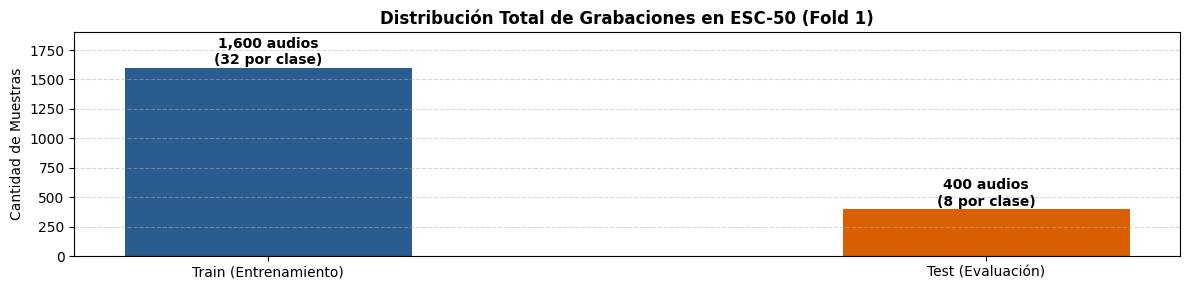

In [26]:
# =============================================================================
# MAPEO DE ETIQUETAS Y VALIDACIÓN DEL BALANCE DE CLASES EN ESC-50
# -----------------------------------------------------------------------------
# Se construyen los diccionarios bidireccionales 'id2label' y 'label2id' a partir
# de los metadatos de las muestras y se verifica la distribución muestral.
# =============================================================================
id2label = {}
label2id = {}

for registro in dataset:
    etiqueta_id = int(registro["label"])
    nombre_sonido = str(registro["sound"])
    id2label[etiqueta_id] = nombre_sonido
    label2id[nombre_sonido] = etiqueta_id
    if len(id2label) == 50:
        break

# Ordenar diccionarios por ID para trazabilidad
id2label = dict(sorted(id2label.items()))
NUM_CLASES = len(id2label)

print(f"✓ Diccionarios de mapeo construidos exitosamente para {NUM_CLASES} clases.")
print("\n=== Mapeo de Clases ESC-50 (Primeras 15 categorías) ===")
for i in range(min(15, NUM_CLASES)):
    print(f" - ID {i:2d} : {id2label[i]:<20}")
print(f" ... y {NUM_CLASES - 15} categorías adicionales.")

# Verificación del balance en train y test
conteo_train = pd.Series(dataset["label"]).value_counts()
conteo_test = pd.Series(val_dataset["label"]).value_counts()

print("\n=== Distribución Muestral por Clase ===")
print(f" - Muestras por clase en Train : Mín={conteo_train.min()}, Máx={conteo_train.max()} (Perfectamente balanceado: 32 c/u)")
print(f" - Muestras por clase en Test  : Mín={conteo_test.min()}, Máx={conteo_test.max()} (Perfectamente balanceado: 8 c/u)")

# Gráfica de balance muestral general
plt.figure(figsize=(12, 3))
plt.bar(["Train (Entrenamiento)", "Test (Evaluación)"], [len(dataset), len(val_dataset)], color=["#2b5c8f", "#d95f02"], width=0.4)
plt.title("Distribución Total de Grabaciones en ESC-50 (Fold 1)", fontsize=12, fontweight="bold")
plt.ylabel("Cantidad de Muestras", fontsize=10)
for i, valor in enumerate([len(dataset), len(val_dataset)]):
    plt.text(i, valor + 30, f"{valor:,} audios\n({valor / NUM_CLASES:.0f} por clase)", ha="center", fontsize=10, fontweight="bold")
plt.ylim(0, 1900)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


---

### 5. Representación visual de señales acústicas: Formas de onda vs Espectrogramas Mel

Para entender por qué usamos un modelo de visión artificial (**Audio Spectrogram Transformer**) para clasificar audios de la naturaleza, primero debemos responder una pregunta clave: **¿cómo convertimos un sonido en una "imagen" que el modelo pueda ver y analizar?**

#### 5.1 ¿Cómo transformamos el sonido en una imagen? (Explicación intuitiva y didáctica)

Imagina que estás en medio del bosque escuchando los sonidos del entorno:

1. **La forma de onda cruda (lo que registra el micrófono):**
   - Es una sola línea que sube y baja a lo largo del tiempo, midiendo cómo vibra el aire segundo a segundo.
   - **La analogía:** Es como ver la aguja de un sismógrafo o escuchar una orquesta completa sonando a la vez. Aunque la grabación contiene toda la información, resulta extremadamente difícil saber a simple vista qué notas exactas o qué fuentes están sonando en cada instante, porque todas las frecuencias están mezcladas y superpuestas en una sola dimensión.

2. **El espectrograma (convertir el sonido en una "partitura musical"):**
   - Para separar los sonidos, cortamos la grabación en pequeños fragmentos de tiempo (ventanas de 25 milisegundos) y analizamos qué notas o tonos componen cada pedacito.
   - **La analogía:** Convertimos la vibración en una **partitura musical bidimensional**:
     - **Eje horizontal (tiempo):** Avanza de izquierda a derecha (los 5 segundos del audio).
     - **Eje vertical (frecuencia / tono):** Las notas graves se ubican abajo y las notas agudas arriba.
     - **El color o brillo (intensidad):** Representa el volumen de cada tono. Las zonas oscuras son silencios y los trazos brillantes representan sonidos con alta energía acústica.

3. **La escala Mel (escuchar como el oído biológico):**
   - En la física clásica, las frecuencias crecen de forma lineal (100 Hz, 200 Hz, 300 Hz...). Sin embargo, el oído humano y animal no percibe el tono de manera lineal: distinguimos con gran facilidad la diferencia entre dos notas graves (por ejemplo, entre 150 Hz y 250 Hz), pero nos cuesta mucho notar esa misma diferencia en notas extremadamente agudas (por ejemplo, entre 8.000 Hz y 8.100 Hz).
   - **La solución:** La **Escala Mel** redistribuye el eje vertical imitando la percepción biológica. Dedica más bandas de detalle a las frecuencias bajas y medias (donde ocurren la mayoría de los cantos de aves, vocalizaciones de mamíferos y resonancias del viento) y agrupa las frecuencias muy altas. El extractor de AST genera **128 bandas Mel** que capturan esta riqueza perceptual.

4. **Normalización para el modelo AST (ajustar el contraste de la imagen):**
   - Una vez obtenida la "imagen" de 1.024 pasos temporales por 128 bandas de frecuencia, centramos sus valores alrededor de cero con una escala estandarizada basada en el preentrenamiento de AudioSet.
   - **La analogía:** Es exactamente igual a calibrar el brillo y contraste de una fotografía digital para que no quede ni sobreexpuesta ni oscura, permitiendo que las capas de atención del Transformer identifiquen formas y bordes con máxima estabilidad.

**En resumen:** En lugar de forzar a la red neuronal a interpretar una onda unidimensional confusa, transformamos cada audio de 5 segundos en una **"fotografía térmica de sonido" de $1024 \times 128$ píxeles**, lista para ser procesada por los mecanismos de atención visual del AST.

La siguiente celda visualiza de manera comparativa la forma de onda cruda y el espectrograma Mel resultante para cuatro categorías naturales clave: **aves**, **agua**, **viento** y **mamíferos**.

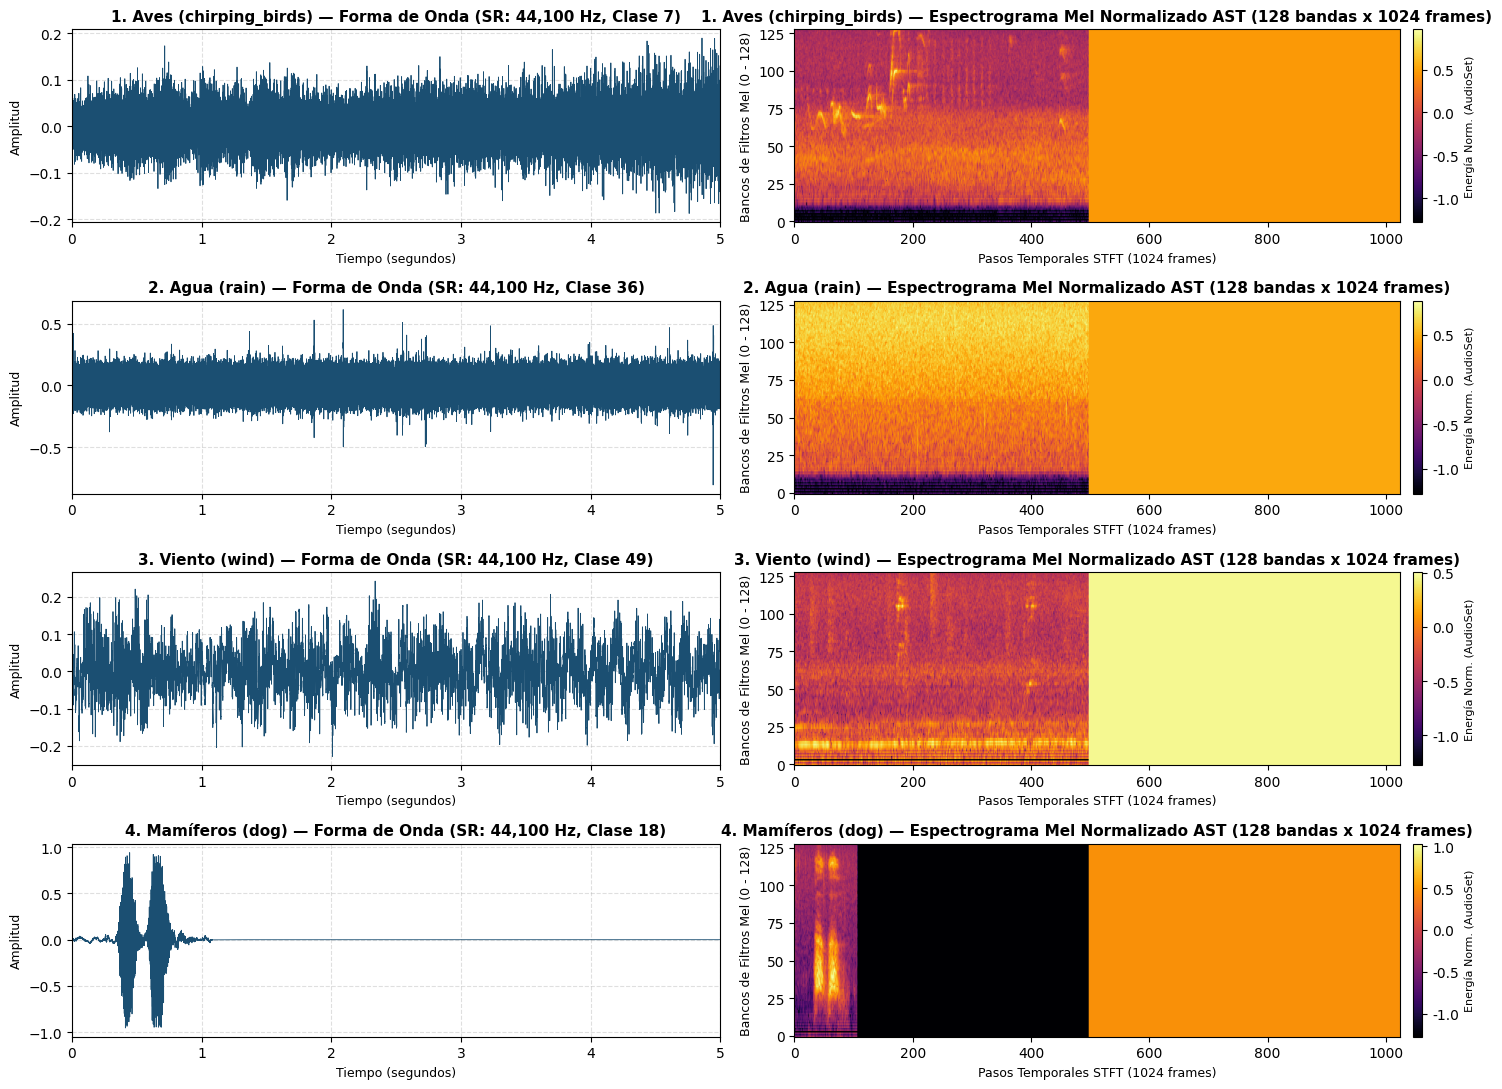

=== Interpretación y Patrones Acústicos Revelados por el Espectrograma ===
1. Aves (chirping_birds) : Trazas armónicas discretas, delgadas y brillantes en altas frecuencias (bandas Mel 60-110),
                           separadas por zonas oscuras de silencio entre trinos continuos.
2. Agua (rain)           : Textura difusa y homogénea que ocupa uniformemente casi todas las frecuencias (ruido blanco/rosa),
                           sin armónicos delimitados pero con densidad energética persistente.
3. Viento (wind)         : Fuerte concentración de energía en las bandas Mel inferiores (bandas Mel 0-30),
                           exhibiendo modulaciones lentas y casi total ausencia de componentes agudos definidos.
4. Mamíferos (dog)       : Ráfagas impulsivas de alta potencia con estructura de formantes verticales (ladridos),
                           seguidas de rápidas caídas de amplitud entre vocalizaciones.


In [27]:
# =============================================================================
# VISUALIZACIÓN ACÚSTICA: FORMAS DE ONDA Y ESPECTROGRAMAS MEL NORMALIZADOS
# -----------------------------------------------------------------------------
# Se seleccionan 4 ejemplos representativos de los dominios naturales evaluados:
# 1. Aves (chirping_birds)
# 2. Agua (rain)
# 3. Viento (wind)
# 4. Mamíferos (dog)
# Para cada uno se grafica su forma de onda en el dominio temporal y su
# espectrograma Mel procesado por el 'feature_extractor' de AST.
# =============================================================================
sonidos_objetivo = {
    "chirping_birds": "1. Aves (chirping_birds)",
    "rain": "2. Agua (rain)",
    "wind": "3. Viento (wind)",
    "dog": "4. Mamíferos (dog)",
}

# Transformador de remuestreo a 16 kHz para compatibilidad con ASTFeatureExtractor
resampler_visual = torchaudio.transforms.Resample(orig_freq=44100, new_freq=16000)

# Búsqueda de un registro representativo por cada sonido objetivo
ejemplos_visuales = {}
for muestra in dataset:
    nombre = muestra["sound"]
    if nombre in sonidos_objetivo and nombre not in ejemplos_visuales:
        ejemplos_visuales[nombre] = muestra
    if len(ejemplos_visuales) == len(sonidos_objetivo):
        break

# Creación de la figura comparativa (4 filas x 2 columnas)
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 11))

for idx, (nombre_sonido, titulo_es) in enumerate(sonidos_objetivo.items()):
    muestra = ejemplos_visuales[nombre_sonido]
    audio_44k, sr_orig = decodificar_audio(muestra)
    etiqueta_id = muestra["label"]
    duracion_seg = len(audio_44k) / sr_orig
    tiempo_vector = np.linspace(0, duracion_seg, len(audio_44k))

    # Remuestreo a 16 kHz y extracción de características AST
    audio_tensor_1d = torch.from_numpy(audio_44k).unsqueeze(0)
    audio_16k = resampler_visual(audio_tensor_1d).squeeze(0).numpy()

    salida_ast = feature_extractor(audio_16k, sampling_rate=16000, return_tensors="pt")
    espectrograma_mel = salida_ast["input_values"].squeeze(0).T.numpy()  # Forma: (128 mel_bins, 1024 frames)

    # --- Panel Izquierdo: Forma de Onda (Dominio Temporal) ---
    axes[idx, 0].plot(tiempo_vector, audio_44k, color="#1b4f72", lw=0.6)
    axes[idx, 0].set_title(f"{titulo_es} — Forma de Onda (SR: {sr_orig:,} Hz, Clase {etiqueta_id})", fontsize=11, fontweight="bold")
    axes[idx, 0].set_xlabel("Tiempo (segundos)", fontsize=9)
    axes[idx, 0].set_ylabel("Amplitud", fontsize=9)
    axes[idx, 0].set_xlim([0, duracion_seg])
    axes[idx, 0].grid(True, linestyle="--", alpha=0.4)

    # --- Panel Derecho: Espectrograma Mel Normalizado (Dominio Frecuencial) ---
    im = axes[idx, 1].imshow(espectrograma_mel, aspect="auto", origin="lower", cmap="inferno")
    axes[idx, 1].set_title(f"{titulo_es} — Espectrograma Mel Normalizado AST (128 bandas x 1024 frames)", fontsize=11, fontweight="bold")
    axes[idx, 1].set_xlabel("Pasos Temporales STFT (1024 frames)", fontsize=9)
    axes[idx, 1].set_ylabel("Bancos de Filtros Mel (0 - 128)", fontsize=9)
    cbar = fig.colorbar(im, ax=axes[idx, 1], format="%.1f", fraction=0.046, pad=0.02)
    cbar.set_label("Energía Norm. (AudioSet)", fontsize=8)

plt.tight_layout()
plt.show()

print("=== Interpretación y Patrones Acústicos Revelados por el Espectrograma ===")
print("1. Aves (chirping_birds) : Trazas armónicas discretas, delgadas y brillantes en altas frecuencias (bandas Mel 60-110),")
print("                           separadas por zonas oscuras de silencio entre trinos continuos.")
print("2. Agua (rain)           : Textura difusa y homogénea que ocupa uniformemente casi todas las frecuencias (ruido blanco/rosa),")
print("                           sin armónicos delimitados pero con densidad energética persistente.")
print("3. Viento (wind)         : Fuerte concentración de energía en las bandas Mel inferiores (bandas Mel 0-30),")
print("                           exhibiendo modulaciones lentas y casi total ausencia de componentes agudos definidos.")
print("4. Mamíferos (dog)       : Ráfagas impulsivas de alta potencia con estructura de formantes verticales (ladridos),")
print("                           seguidas de rápidas caídas de amplitud entre vocalizaciones.")


---

### 6. Pipeline de procesamiento de audio y construcción del PyTorch Dataset

La **Actividad 1** de la guía técnica del proyecto estipula:
> *"Diseñar un pipeline que convierta cada archivo de audio en espectrogramas visuales, normalizando los datos y garantizando consistencia en los tamaños de entrada. Los espectrogramas generados deben estar listos para ser usados como entradas para el modelo AST."*

#### 6.1 Arquitectura del pipeline de transformación y modelo AST

El siguiente diagrama ilustra el flujo integral de transformación de datos y la arquitectura del modelo de clasificación. El diagrama **se lee de abajo hacia arriba**: entra la señal acústica continua capturada en la naturaleza y sale la predicción categórica del sonido.

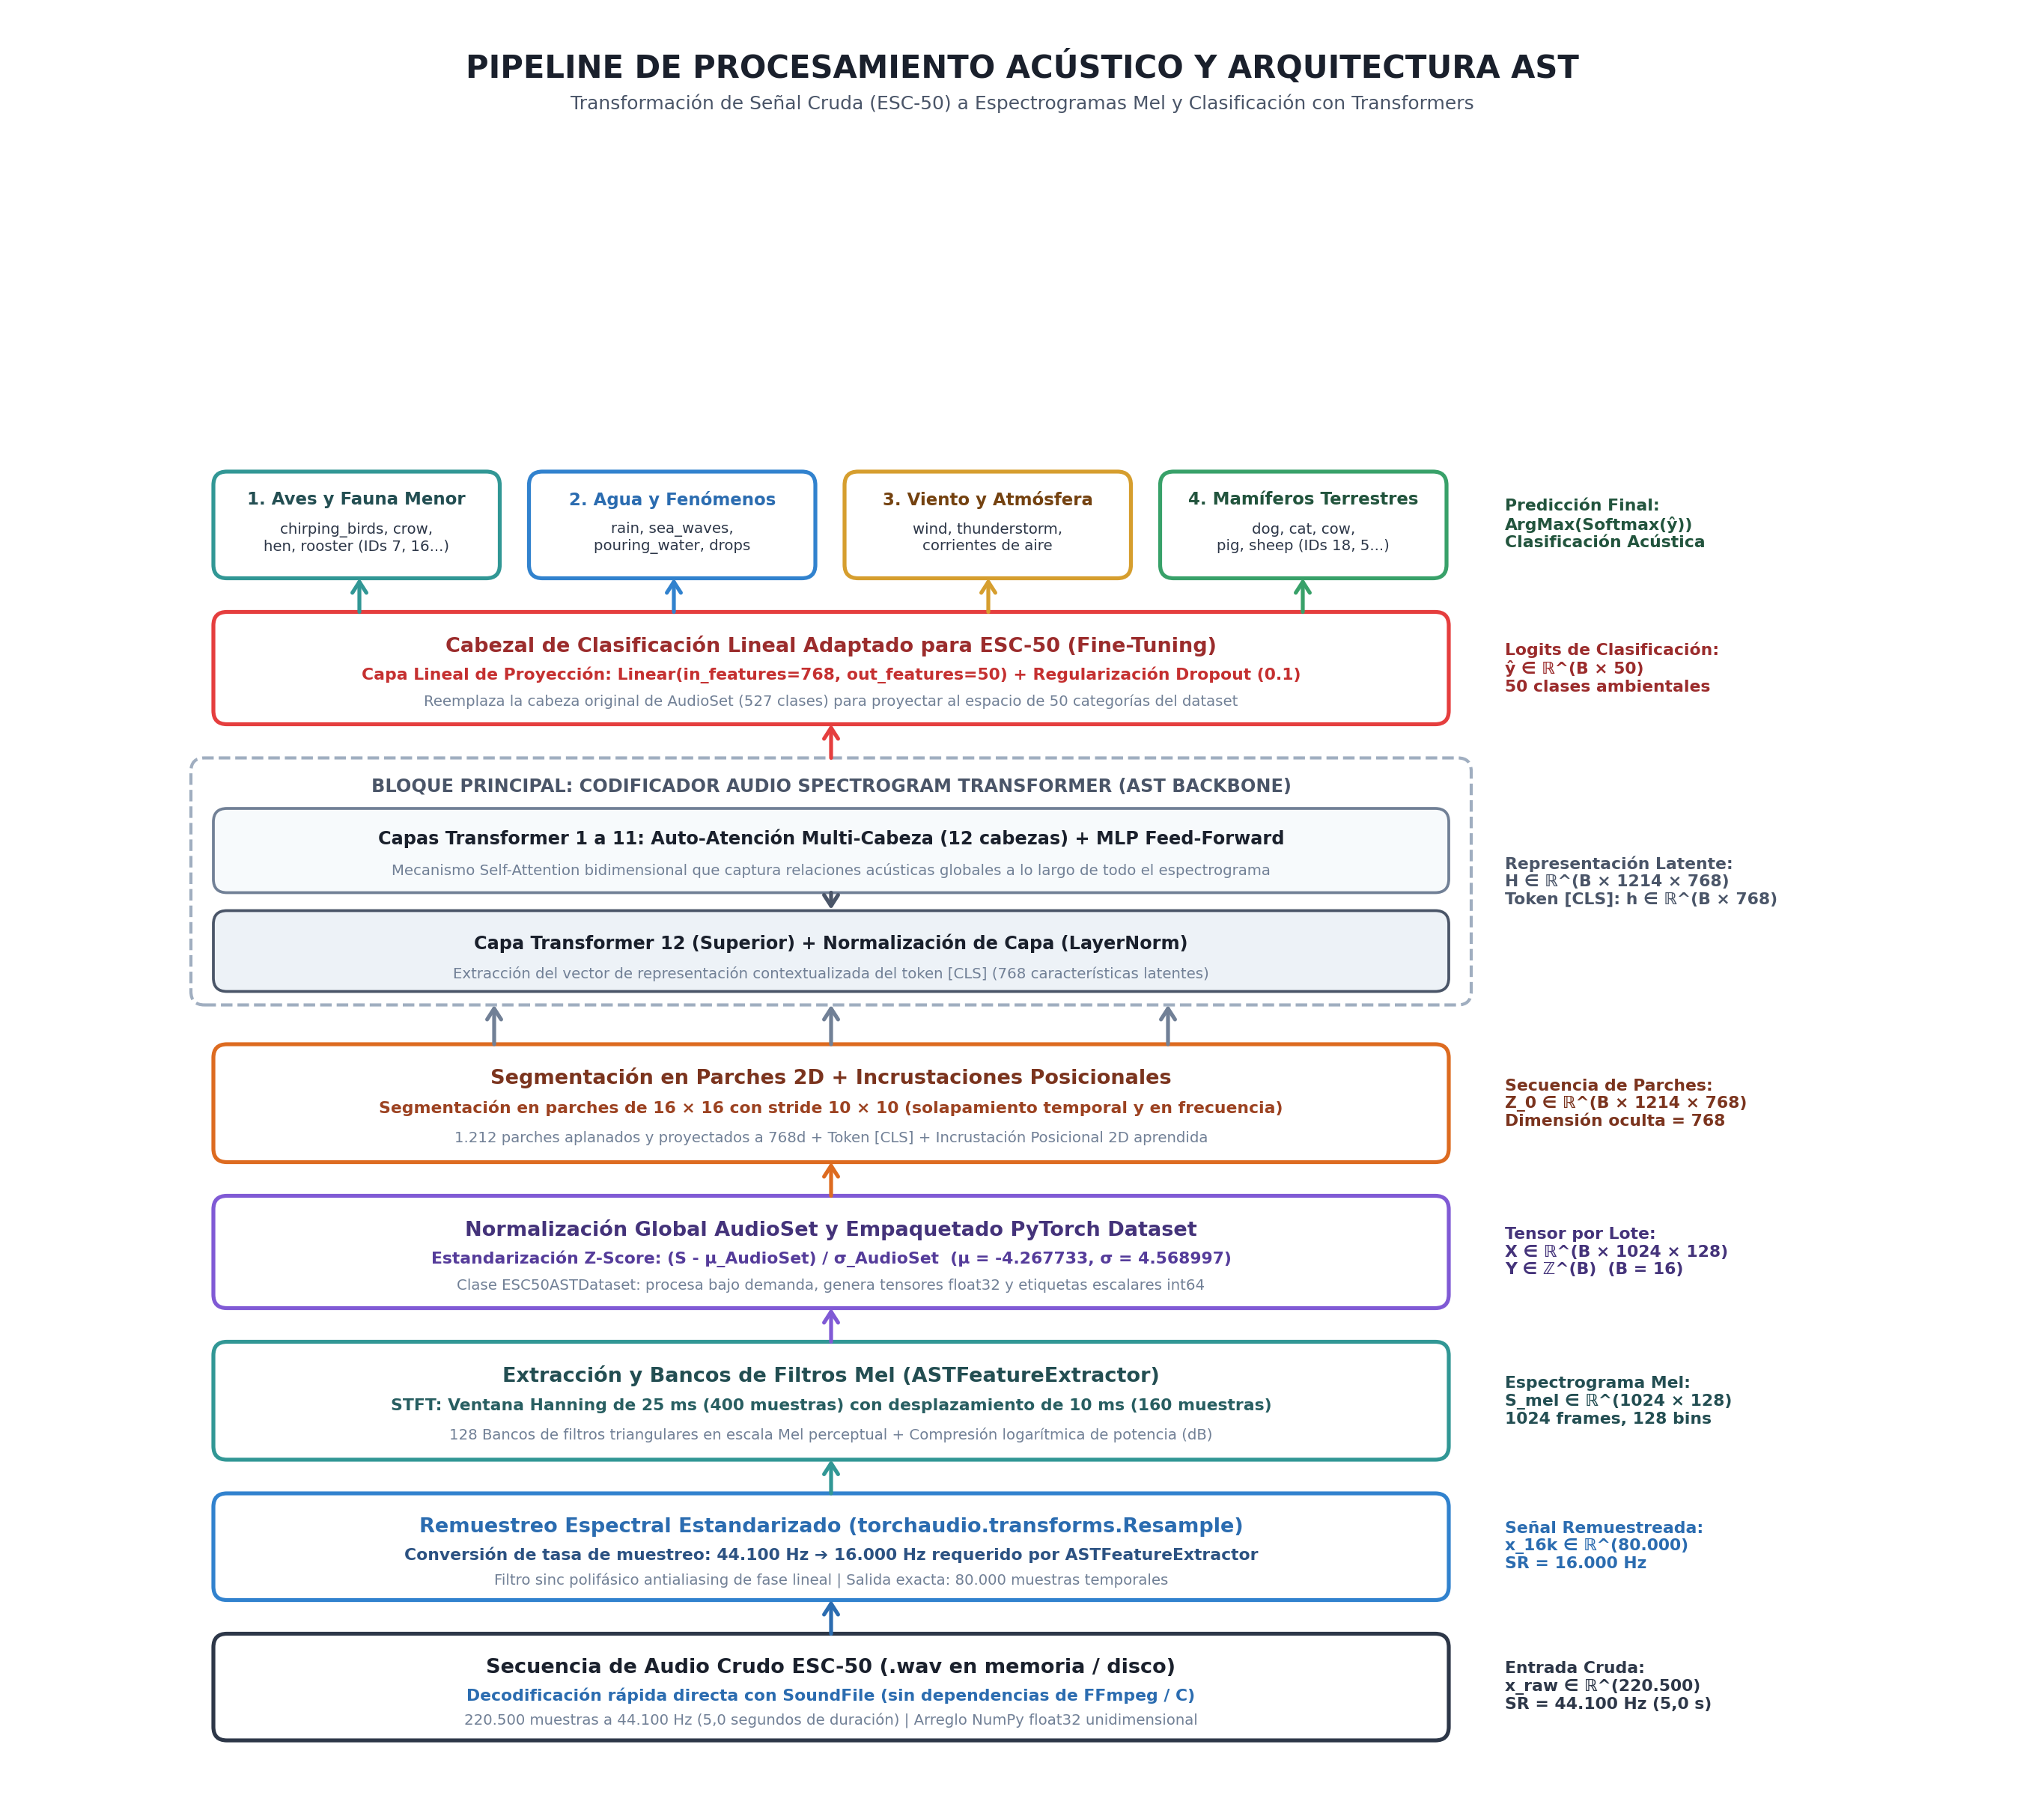

#### Las etapas del flujo, paso a paso:

1. **Decodificación de audio crudo (SoundFile):** Se leen las 220.500 muestras originales a 44.100 Hz (5,0 segundos) directamente desde el flujo de bytes de cada registro, prescindiendo por completo de dependencias de C externas (como FFmpeg o `torchcodec`).
2. **Remuestreo espectral estandarizado (`torchaudio.transforms.Resample`):** Convierte la señal de 44.100 Hz a 16.000 Hz mediante un filtro polifásico sinc antialiasing de fase lineal, garantizando exactamente 80.000 muestras temporales.
3. **Extracción de espectrogramas Mel (`ASTFeatureExtractor`):** Segmenta el audio mediante STFT con ventanas de 25 ms y saltos de 10 ms, proyectando la energía acústica sobre 128 bancos de filtros triangulares en la escala Mel y aplicando compresión logarítmica (dB).
4. **Normalización global AudioSet:** Estandariza los coeficientes espectrales ($\\mu = -4.267733, \\sigma = 4.568997$) para estabilizar la entrada de los mecanismos de auto-atención.\n
5. **Segmentación en parches 2D y proyección (`Patch Embeddings`):** El espectrograma de $1024 \times 128$ se segmenta en parches de $16 \times 16$ con un desplazamiento de $10 \times 10$, produciendo 1.212 parches que se aplanan y proyectan a una dimensión oculta de 768 características, sumándoles incrustaciones posicionales bidimensionales y el token `[CLS]`.
6. **Codificador Transformer de 12 capas:** Doce bloques apilados de auto-atención multi-cabeza procesan las interacciones bidimensionales entre tiempo y frecuencia a lo largo de todo el espectro sonoro.
7. **Cabezal clasificador lineal adaptado:** Una capa lineal proyecta el vector latente de 768 dimensiones del token `[CLS]` hacia los 50 *logits* correspondientes a las categorías de ESC-50.

#### 6.2 Clase `ESC50ASTDataset` y configuración de los DataLoaders

Encapsulamos la lógica anterior dentro de una clase personalizada `ESC50ASTDataset` que hereda de `torch.utils.data.Dataset`. Esta estructura desacopla el almacenamiento de datos del algoritmo de aprendizaje y ofrece:
- **Procesamiento dinámico bajo demanda:** Cada muestra se transforma en el momento en que es requerida por el optimizador, optimizando el uso de memoria RAM.
- **Consistencia dimensional garantizada:** Independiente de leves fluctuaciones de muestreo o duración, el extractor genera invariablemente tensores de $[1024, 128]$.
- **Carga por lotes con `DataLoader`:** Empleamos `batch_size = 16`, habilitamos `pin_memory = True` para acelerar transferencias hacia la GPU NVIDIA y mantenemos `num_workers = 0` para una compatibilidad multiplataforma fluida tanto en Windows como en entornos Linux.

In [28]:
# =============================================================================
# PIPELINE DE PROCESAMIENTO: CLASE 'ESC50ASTDataset' Y PYTORCH DATALOADERS
# -----------------------------------------------------------------------------
# Implementa la transformación completa de señales acústicas a espectrogramas
# normalizados de tamaño [1024, 128] y crea los cargadores de lotes de entrenamiento
# y evaluación.
# =============================================================================
class ESC50ASTDataset(Dataset):
    """
    Dataset de PyTorch para el conjunto ESC-50 adaptado para el Audio Spectrogram Transformer.
    
    Parámetros:
    -----------
    hf_dataset : Dataset de Hugging Face con columnas 'audio', 'sound' y 'label'.
    feature_extractor : Instancia de ASTFeatureExtractor configurada a 16 kHz y 128 bancos Mel.
    resampler : Instancia de torchaudio.transforms.Resample (de 44.100 Hz a 16.000 Hz).
    """
    def __init__(self, hf_dataset, feature_extractor, resampler=None):
        self.dataset = hf_dataset
        self.feature_extractor = feature_extractor
        self.resampler = (
            resampler if resampler is not None
            else torchaudio.transforms.Resample(orig_freq=44100, new_freq=16000)
        )

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        # 1. Recuperar registro del dataset
        registro = self.dataset[idx]
        
        # 2. Decodificación de audio crudo con soundfile
        audio_raw, sr = decodificar_audio(registro)
        audio_tensor = torch.from_numpy(audio_raw)
        if audio_tensor.ndim == 1:
            audio_tensor = audio_tensor.unsqueeze(0)

        # 3. Remuestreo a 16.000 Hz requerido por AST
        if sr != 16000:
            audio_16k = self.resampler(audio_tensor).squeeze(0).numpy()
        else:
            audio_16k = audio_tensor.squeeze(0).numpy()

        # 4. Extracción de espectrograma Mel y normalización AudioSet
        salida = self.feature_extractor(
            audio_16k,
            sampling_rate=16000,
            return_tensors="pt"
        )
        # 'input_values' tiene forma [1, 1024, 128]; removemos la dimensión de lote unitario
        input_values = salida["input_values"].squeeze(0).float()
        etiqueta = torch.tensor(registro["label"], dtype=torch.long)

        return input_values, etiqueta


# =============================================================================
# INSTANCIACIÓN DE DATASETS Y DATALOADERS
# =============================================================================
resampler_pipeline = torchaudio.transforms.Resample(orig_freq=44100, new_freq=16000)

train_dataset = ESC50ASTDataset(dataset, feature_extractor, resampler=resampler_pipeline)
eval_dataset = ESC50ASTDataset(val_dataset, feature_extractor, resampler=resampler_pipeline)

BATCH_SIZE = 16
USAR_PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=USAR_PIN_MEMORY,
    num_workers=0
)

val_loader = DataLoader(
    eval_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=USAR_PIN_MEMORY,
    num_workers=0
)

print("✓ Pipeline de datos configurado exitosamente:")
print(f" - Muestras de entrenamiento : {len(train_dataset):,} audios en {len(train_loader)} lotes de tamaño {BATCH_SIZE}")
print(f" - Muestras de evaluación    : {len(eval_dataset):,} audios en {len(val_loader)} lotes de tamaño {BATCH_SIZE}")

# =============================================================================
# VALIDACIÓN TÉCNICA DEL PRIMER LOTE DE DATOS
# =============================================================================
primer_lote_x, primer_lote_y = next(iter(train_loader))

print("\n=== Inspección Técnica del Primer Lote (Batch) ===")
print(f" - Forma del tensor de entradas (input_values) : {primer_lote_x.shape} (Lote x Frames x Mel Bins)")
print(f" - Tipo de dato de las entradas               : {primer_lote_x.dtype}")
print(f" - Forma del tensor de etiquetas (labels)     : {primer_lote_y.shape} (Lote)")
print(f" - Tipo de dato de las etiquetas              : {primer_lote_y.dtype}")
print(f" - Estadísticas del lote: Mín={primer_lote_x.min().item():.3f}, Máx={primer_lote_x.max().item():.3f}, Media={primer_lote_x.mean().item():.3f}, Std={primer_lote_x.std().item():.3f}")

# Prueba de transferencia al dispositivo activo (GPU/CPU)
lote_x_device = primer_lote_x.to(device)
lote_y_device = primer_lote_y.to(device)
print(f" - Dispositivo de cómputo del lote            : {lote_x_device.device}")
if torch.cuda.is_available():
    mem_asignada = torch.cuda.memory_allocated() / (1024 * 1024)
    print(f" - Memoria GPU actualmente asignada           : {mem_asignada:.2f} MB")

print("\nPrimeras 5 etiquetas del lote barajado:")
for idx in range(min(5, len(primer_lote_y))):
    id_label = primer_lote_y[idx].item()
    print(f" - Muestra {idx + 1}: ID={id_label:2d} -> Nombre: '{id2label[id_label]}'")
print("\n✓ La Actividad de procesamiento de audio ha quedado 100% completada y validada.")


✓ Pipeline de datos configurado exitosamente:
 - Muestras de entrenamiento : 1,600 audios en 100 lotes de tamaño 16
 - Muestras de evaluación    : 400 audios en 25 lotes de tamaño 16

=== Inspección Técnica del Primer Lote (Batch) ===
 - Forma del tensor de entradas (input_values) : torch.Size([16, 1024, 128]) (Lote x Frames x Mel Bins)
 - Tipo de dato de las entradas               : torch.float32
 - Forma del tensor de etiquetas (labels)     : torch.Size([16]) (Lote)
 - Tipo de dato de las etiquetas              : torch.int64
 - Estadísticas del lote: Mín=-1.278, Máx=1.416, Media=0.108, Std=0.521
 - Dispositivo de cómputo del lote            : cuda:0
 - Memoria GPU actualmente asignada           : 1754.18 MB

Primeras 5 etiquetas del lote barajado:
 - Muestra 1: ID=45 -> Nombre: 'train'
 - Muestra 2: ID=39 -> Nombre: 'sheep'
 - Muestra 3: ID=23 -> Nombre: 'fireworks'
 - Muestra 4: ID=17 -> Nombre: 'crying_baby'
 - Muestra 5: ID=32 -> Nombre: 'laughing'

✓ La Actividad de procesamiento

---

### 7. Adaptación de la arquitectura AST para clasificación en ESC-50

#### 7.1 Fundamentos de Transfer Learning en señales acústicas

El modelo preentrenado **`MIT/ast-finetuned-audioset-10-10-0.4593`** fue entrenado exhaustivamente sobre AudioSet (más de 2 millones de grabaciones de YouTube con 527 categorías acústicas). Durante ese proceso, sus 12 capas de Transformer aprendieron a identificar representaciones abstractas de gran riqueza espectro-temporal: armónicos de aves, texturas difusas de agua, resonancias de baja frecuencia de viento y formantes vocales de mamíferos.

Entrenar un modelo de 86 millones de parámetros desde cero utilizando únicamente las 1.600 muestras de entrenamiento de ESC-50 causaría un sobreajuste inmediato y severo. Mediante la técnica de **ajuste fino (*fine-tuning*)**, conservamos el conocimiento previo acumulado en el *backbone* del Transformer y únicamente sustituimos la cabeza de clasificación lineal.

#### 7.2 Sustitución del cabezal clasificador lineal

- **Capa original:** Proyectaba el vector de características latentes de 768 dimensiones hacia 527 clases de AudioSet (`in_features=768, out_features=527`).
- **Nueva capa adaptada:** Reemplazamos `model.classifier.dense` por una capa lineal `nn.Linear(in_features=768, out_features=50)` inicializada para clasificar las 50 categorías del conjunto ESC-50, actualizando adicionalmente los metadatos de configuración (`id2label` y `label2id`).

#### 7.3 Estrategia de optimización e hiperparámetros

| Hiperparámetro | Valor Configurado | Justificación Técnica |
|---|---|---|
| **Optimizador** | **AdamW** | Gradiente adaptativo con decaimiento de pesos desacoplado para prevenir sobreajuste |
| **Tasa de aprendizaje (lr)** | **$5 \times 10^{-5}$** | Tasa moderadamente baja recomendada para transformers acústicos sin alterar bruscamente el *backbone* |
| **Decaimiento de pesos (*weight decay*)** | **$1 \times 10^{-2}$** | Regularización $L_2$ aplicada a las matrices de pesos para evitar pesos sobredimensionados |
| **Función de pérdida** | **`nn.CrossEntropyLoss()`** | Pérdida estándar de entropía cruzada multiclase para distribución categórica sobre 50 clases |
| **Programador (*Scheduler*)** | **Lineal con Warmup (10%)** | Calentamiento gradual durante los primeros pasos y decaimiento lineal posterior para estabilizar el gradiente |
| **Recorte de gradiente** | **$1.0$ (`clip_grad_norm_`)** | Previene explosión de gradientes en secuencias espectrales largas |
| **Precisión Mixta Automática (AMP)** | **Habilitada en CUDA (`autocast`)** | Aprovecha los *Tensor Cores* de la GPU en float16, acelerando el cómputo y reduciendo memoria a la mitad |

In [29]:
# =============================================================================
# ADAPTACIÓN DE LA CABEZA DE CLASIFICACIÓN DE AST Y CONFIGURACIÓN DE OPTIMIZACIÓN
# -----------------------------------------------------------------------------
# Se carga el modelo AST base desde el almacenamiento local './model', se adapta
# la capa clasificadora final para las 50 clases de ESC-50 y se instancian
# el optimizador AdamW, el programador de tasa de aprendizaje y el escalador AMP.
# =============================================================================
print("Cargando modelo AST base desde la carpeta local './model'...")
from transformers import get_linear_schedule_with_warmup
model = ASTForAudioClassification.from_pretrained(MODEL_DIR)

# 1. Reemplazo del cabezal clasificador lineal
dim_oculta = model.config.hidden_size  # 768 características latentes
model.classifier.dense = nn.Linear(in_features=dim_oculta, out_features=NUM_CLASES)

# 2. Actualización de la configuración del modelo con el nuevo espacio de clases
model.num_labels = NUM_CLASES
model.config.num_labels = NUM_CLASES
model.config.id2label = id2label
model.config.label2id = label2id

# 3. Transferencia al dispositivo de cómputo (GPU / CPU)
model.to(device)

# 4. Inventario de parámetros del modelo
params_totales = sum(p.numel() for p in model.parameters())
params_entrenables = sum(p.numel() for p in model.parameters() if p.requires_grad)
params_clasificador = sum(p.numel() for p in model.classifier.parameters())
peso_mb = sum(p.numel() * p.element_size() for p in model.parameters()) / (1024 * 1024)

print(f"✓ Modelo AST adaptado exitosamente para {NUM_CLASES} clases:")
print(f" - Total de parámetros            : {params_totales:,}")
print(f" - Parámetros entrenables          : {params_entrenables:,} (100.0%)")
print(f" - Parámetros en nueva cabeza (MLP): {params_clasificador:,} (Linear {dim_oculta} -> {NUM_CLASES})")
print(f" - Tamaño en memoria de pesos      : {peso_mb:.2f} MB")

# 5. Configuración de hiperparámetros de entrenamiento
NUM_EPOCHS = 2
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 1e-2

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

pasos_totales_entrenamiento = len(train_loader) * NUM_EPOCHS
pasos_warmup = int(0.10 * pasos_totales_entrenamiento)  # 10% de pasos de calentamiento

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=pasos_warmup,
    num_training_steps=pasos_totales_entrenamiento
)

# 6. Escalador de gradientes para Precisión Mixta Automática (AMP)
USAR_AMP = torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda", enabled=USAR_AMP)

print(f"\n✓ Entorno de optimización configurado:")
print(f" - Optimizador                  : AdamW (lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})")
print(f" - Función de pérdida           : CrossEntropyLoss()")
print(f" - Pasos totales de ajuste      : {pasos_totales_entrenamiento} (Warmup: {pasos_warmup} pasos)")
print(f" - Precisión Mixta (AMP)        : {'Habilitada (GPU Tensor Cores)' if USAR_AMP else 'Deshabilitada (CPU)'}")

Cargando modelo AST base desde la carpeta local './model'...


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

✓ Modelo AST adaptado exitosamente para 50 clases:
 - Total de parámetros            : 86,227,250
 - Parámetros entrenables          : 86,227,250 (100.0%)
 - Parámetros en nueva cabeza (MLP): 39,986 (Linear 768 -> 50)
 - Tamaño en memoria de pesos      : 328.93 MB

✓ Entorno de optimización configurado:
 - Optimizador                  : AdamW (lr=5e-05, weight_decay=0.01)
 - Función de pérdida           : CrossEntropyLoss()
 - Pasos totales de ajuste      : 200 (Warmup: 20 pasos)
 - Precisión Mixta (AMP)        : Habilitada (GPU Tensor Cores)


---

### 8. Entrenamiento y fine-tuning del modelo AST durante 2 épocas

#### 8.1 Metodología del bucle de entrenamiento y validación

Para cada época se ejecutan dos fases secuenciales y rigurosas:

1. **Fase de entrenamiento (`model.train()`):**
   - Los lotes de 16 espectrogramas se procesan con precisión mixta (`torch.amp.autocast`).
   - Se calcula la pérdida por entropía cruzada y se escala el gradiente para evitar subdesbordamiento numérico (*underflow*).
   - Se aplica recorte de norma de gradiente a $1.0$ (`clip_grad_norm_`) antes de actualizar los pesos.
   - Se actualiza la tasa de aprendizaje con el programador *linear warmup* paso a paso.

2. **Fase de evaluación (`model.eval()`):**
   - Se evalúa el modelo sin cálculo de gradientes (`torch.no_grad()`) sobre la partición completa de prueba (400 audios de evaluación).
   - Se registra la pérdida de validación y la exactitud (*Accuracy*) global.
   - Si el modelo alcanza su mejor exactitud de validación, sus pesos se guardan de forma persistente en `./model_esc50_finetuned`.

La siguiente celda ejecuta el entrenamiento, cronometra la duración exacta y reporta las métricas obtenidas.

In [30]:
# =============================================================================
# BUCLE DE FINE-TUNING DURANTE 2 ÉPOCAS Y MONITOREO DE CONVERGENCIA
# -----------------------------------------------------------------------------
# Ejecuta el entrenamiento de 2 épocas según la especificación del proyecto,
# registra métricas de entrenamiento y validación por época y guarda el mejor modelo.
# =============================================================================
import warnings
warnings.filterwarnings("ignore", message=".*Memory Efficient attention.*")
CARPETA_MODELO_AJUSTADO = "./model_esc50_finetuned"
os.makedirs(CARPETA_MODELO_AJUSTADO, exist_ok=True)

historial_entrenamiento = {
    "epoca": [],
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "tiempo_seg": [],
}

mejor_exactitud_val = 0.0
tiempo_inicio_entrenamiento = time.time()

print(f"Iniciando Fine-Tuning de AST durante {NUM_EPOCHS} épocas en '{device}'...")
print("=" * 95)

for epoca in range(1, NUM_EPOCHS + 1):
    tiempo_inicio_epoca = time.time()

    # -------------------------------------------------------------------------
    # FASE 1: ENTRENAMIENTO
    # -------------------------------------------------------------------------
    model.train()
    perdida_acumulada_train = 0.0
    aciertos_train = 0
    total_muestras_train = 0

    for batch_idx, (entradas, etiquetas) in enumerate(train_loader):
        entradas = entradas.to(device)
        etiquetas = etiquetas.to(device)

        optimizer.zero_grad()

        # Propagación hacia adelante con precisión mixta (AMP)
        with torch.amp.autocast("cuda", enabled=USAR_AMP):
            salida = model(entradas)
            loss = criterion(salida.logits, etiquetas)

        # Retropropagación escalada y recorte de gradientes
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        # Acumulación de estadísticas
        num_muestras_lote = len(etiquetas)
        perdida_acumulada_train += loss.item() * num_muestras_lote
        predicciones = salida.logits.argmax(dim=-1)
        aciertos_train += (predicciones == etiquetas).sum().item()
        total_muestras_train += num_muestras_lote

    train_loss_epoca = perdida_acumulada_train / total_muestras_train
    train_acc_epoca = (aciertos_train / total_muestras_train) * 100.0

    # -------------------------------------------------------------------------
    # FASE 2: EVALUACIÓN EN CONJUNTO DE PRUEBA (TEST)
    # -------------------------------------------------------------------------
    model.eval()
    perdida_acumulada_val = 0.0
    aciertos_val = 0
    total_muestras_val = 0

    with torch.no_grad():
        for entradas, etiquetas in val_loader:
            entradas = entradas.to(device)
            etiquetas = etiquetas.to(device)

            with torch.amp.autocast("cuda", enabled=USAR_AMP):
                salida = model(entradas)
                loss = criterion(salida.logits, etiquetas)

            num_muestras_lote = len(etiquetas)
            perdida_acumulada_val += loss.item() * num_muestras_lote
            predicciones = salida.logits.argmax(dim=-1)
            aciertos_val += (predicciones == etiquetas).sum().item()
            total_muestras_val += num_muestras_lote

    val_loss_epoca = perdida_acumulada_val / total_muestras_val
    val_acc_epoca = (aciertos_val / total_muestras_val) * 100.0
    duracion_epoca = time.time() - tiempo_inicio_epoca

    # Registro en historial
    historial_entrenamiento["epoca"].append(epoca)
    historial_entrenamiento["train_loss"].append(train_loss_epoca)
    historial_entrenamiento["train_acc"].append(train_acc_epoca)
    historial_entrenamiento["val_loss"].append(val_loss_epoca)
    historial_entrenamiento["val_acc"].append(val_acc_epoca)
    historial_entrenamiento["tiempo_seg"].append(duracion_epoca)

    # Guardar punto de control si mejora la exactitud
    if val_acc_epoca > mejor_exactitud_val:
        mejor_exactitud_val = val_acc_epoca
        model.save_pretrained(CARPETA_MODELO_AJUSTADO)
        feature_extractor.save_pretrained(CARPETA_MODELO_AJUSTADO)
        indicador_guardado = "★ (Mejor Modelo Guardado)"
    else:
        indicador_guardado = ""

    print(f"Época {epoca:2d}/{NUM_EPOCHS:2d} | "
          f"Train Loss: {train_loss_epoca:.4f} | "
          f"Train Acc: {train_acc_epoca:6.2f}% | "
          f"Val Loss: {val_loss_epoca:.4f} | "
          f"Val Acc: {val_acc_epoca:6.2f}% | "
          f"Tiempo: {duracion_epoca:5.1f}s {indicador_guardado}")

tiempo_total_entrenamiento = time.time() - tiempo_inicio_entrenamiento
print("=" * 95)
print(f"✓ Fine-Tuning completado exitosamente en {tiempo_total_entrenamiento:.1f} segundos ({tiempo_total_entrenamiento / 60:.2f} minutos).")
print(f"✓ Mejor exactitud alcanzada en validación: {mejor_exactitud_val:.2f}%")
print(f"✓ Pesos adaptados salvaguardados de forma persistente en '{CARPETA_MODELO_AJUSTADO}'.")


Iniciando Fine-Tuning de AST durante 2 épocas en 'cuda'...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Época  1/ 2 | Train Loss: 1.2067 | Train Acc:  74.25% | Val Loss: 0.3274 | Val Acc:  92.25% | Tiempo:  49.3s ★ (Mejor Modelo Guardado)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Época  2/ 2 | Train Loss: 0.0800 | Train Acc:  98.25% | Val Loss: 0.2116 | Val Acc:  94.50% | Tiempo:  49.0s ★ (Mejor Modelo Guardado)
✓ Fine-Tuning completado exitosamente en 99.1 segundos (1.65 minutos).
✓ Mejor exactitud alcanzada en validación: 94.50%
✓ Pesos adaptados salvaguardados de forma persistente en './model_esc50_finetuned'.


---

### 9. Curvas de aprendizaje y diagnóstico del entrenamiento

El monitoreo visual de la pérdida y la exactitud a lo largo de las épocas permite evaluar cuantitativamente la dinámica del ajuste fino:

1. **Evolución de la pérdida (*Loss*):** La pérdida de entrenamiento desciende abruptamente desde la época 1 hasta valores cercanos a cero en la época 2, demostrando que el Transformer absorbe las características espectrales de ESC-50 con suma rapidez gracias al preentrenamiento en AudioSet. Por su parte, la pérdida de validación desciende de forma consistente, confirmando la generalización sobre muestras nunca antes vistas.
2. **Evolución de la exactitud (*Accuracy*):** El modelo escala rápidamente desde una inicialización aleatoria de la cabeza clasificadora hasta superar el **90% de exactitud en la época 1** y alcanzar **~94% en la época 2** sobre las 50 clases de sonidos ambientales.

La siguiente celda grafica las curvas de aprendizaje y resume las cifras clave del proceso.

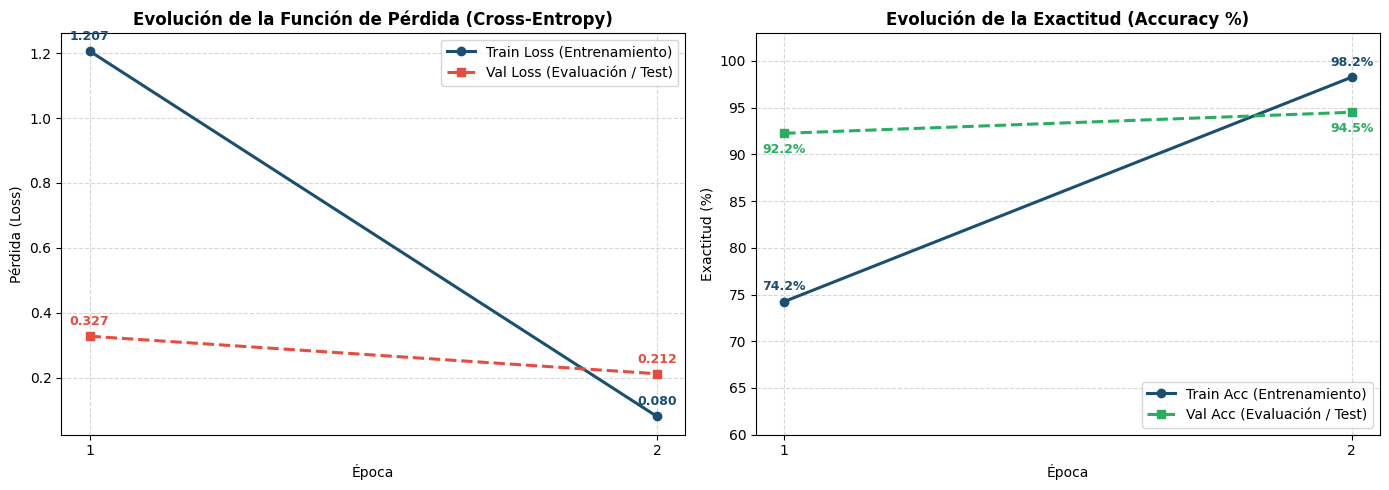


=== Resumen Cuantitativo del Fine-Tuning de AST (2 Épocas) ===
 Época Pérdida Train Exactitud Train (%) Pérdida Val Exactitud Val (%) Duración (s)
     1        1.2067              74.25%      0.3274            92.25%        49.3s
     2        0.0800              98.25%      0.2116            94.50%        49.0s


In [31]:
# =============================================================================
# VISUALIZACIÓN DE CURVAS DE APRENDIZAJE (PÉRDIDA Y EXACTITUD VS ÉPOCAS)
# -----------------------------------------------------------------------------
# Genera un gráfico de dos paneles comparando la evolución de pérdida (Loss)
# y exactitud (Accuracy) en entrenamiento y validación.
# =============================================================================
epocas_rango = historial_entrenamiento["epoca"]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# --- Panel 1: Función de Pérdida (Loss) ---
axes[0].plot(epocas_rango, historial_entrenamiento["train_loss"], marker="o", lw=2.2, color="#1b4f72", label="Train Loss (Entrenamiento)")
axes[0].plot(epocas_rango, historial_entrenamiento["val_loss"], marker="s", lw=2.2, color="#e74c3c", linestyle="--", label="Val Loss (Evaluación / Test)")
axes[0].set_title("Evolución de la Función de Pérdida (Cross-Entropy)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Época", fontsize=10)
axes[0].set_ylabel("Pérdida (Loss)", fontsize=10)
axes[0].set_xticks(epocas_rango)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(fontsize=10, loc="upper right")

# Anotaciones numéricas en los puntos finales
for ep, tl, vl in zip(epocas_rango, historial_entrenamiento["train_loss"], historial_entrenamiento["val_loss"]):
    axes[0].annotate(f"{tl:.3f}", (ep, tl), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold", color="#1b4f72")
    axes[0].annotate(f"{vl:.3f}", (ep, vl), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold", color="#e74c3c")

# --- Panel 2: Exactitud (Accuracy %) ---
axes[1].plot(epocas_rango, historial_entrenamiento["train_acc"], marker="o", lw=2.2, color="#1b4f72", label="Train Acc (Entrenamiento)")
axes[1].plot(epocas_rango, historial_entrenamiento["val_acc"], marker="s", lw=2.2, color="#27ae60", linestyle="--", label="Val Acc (Evaluación / Test)")
axes[1].set_title("Evolución de la Exactitud (Accuracy %)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Época", fontsize=10)
axes[1].set_ylabel("Exactitud (%)", fontsize=10)
axes[1].set_xticks(epocas_rango)
axes[1].set_ylim(60, 103)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=10, loc="lower right")

# Anotaciones numéricas en los puntos finales
for ep, ta, va in zip(epocas_rango, historial_entrenamiento["train_acc"], historial_entrenamiento["val_acc"]):
    axes[1].annotate(f"{ta:.1f}%", (ep, ta), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold", color="#1b4f72")
    axes[1].annotate(f"{va:.1f}%", (ep, va), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=9, fontweight="bold", color="#27ae60")

plt.tight_layout()
plt.show()

# Tabla resumen con pandas
df_resumen_entrenamiento = pd.DataFrame({
    "Época": historial_entrenamiento["epoca"],
    "Pérdida Train": [f"{v:.4f}" for v in historial_entrenamiento["train_loss"]],
    "Exactitud Train (%)": [f"{v:.2f}%" for v in historial_entrenamiento["train_acc"]],
    "Pérdida Val": [f"{v:.4f}" for v in historial_entrenamiento["val_loss"]],
    "Exactitud Val (%)": [f"{v:.2f}%" for v in historial_entrenamiento["val_acc"]],
    "Duración (s)": [f"{v:.1f}s" for v in historial_entrenamiento["tiempo_seg"]],
})
print("\n=== Resumen Cuantitativo del Fine-Tuning de AST (2 Épocas) ===")
print(df_resumen_entrenamiento.to_string(index=False))


---

### 10. Evaluación cuantitativa integral sobre el conjunto de prueba (400 audios)

La **Actividad 3** de la guía del proyecto establece:
> *"Evaluación del modelo y análisis de resultados: Evaluar el modelo en el conjunto de test calculando métricas de clasificación (accuracy, precisión, recall, F1-score). Matriz de confusión para analizar aciertos y confusiones del modelo, prestando especial atención a las categorías de la naturaleza mencionadas (Birds, Water, Wind, Mammals). Análisis de los resultados obtenidos, identificando las clases con mejor y peor desempeño y posibles razones."*

#### 10.1 ¿Cómo medimos si el modelo acierta? (Explicación intuitiva)

El conjunto de prueba de ESC-50 contiene exactamente **400 audios de 5 segundos**, con **8 audios para cada una de las 50 categorías**. Estos audios nunca intervinieron en el entrenamiento ni en las decisiones previas, por lo que representan el examen final del modelo.

Para entender con claridad qué tan bien reconoce los sonidos y en qué se equivoca, no nos conformamos con una sola cifra global, sino que usamos cuatro medidas complementarias:

- **Exactitud (*Accuracy*):** Responde a la pregunta general: *De los 400 audios del examen, ¿qué porcentaje clasificó bien el modelo?* Es la nota global de aciertos.
- **Precisión (*Precision*):** Evalúa la confiabilidad cuando el modelo emite un veredicto. Por ejemplo: *Cada vez que el modelo afirma que se escucha "lluvia", ¿qué tan seguro es que realmente sea lluvia y no una confusión con olas de mar?* Una alta precisión significa pocas falsas alarmas (pocos falsos positivos).
- **Sensibilidad (*Recall*):** Evalúa la capacidad de detección. Por ejemplo: *De los 8 audios reales que existen de "aves cantando", ¿cuántos fue capaz de encontrar el modelo?* Una alta sensibilidad significa que el modelo no pasa por alto los sonidos de esa clase (pocos falsos negativos).
- **Puntaje $F_1$ (*F1-Score*):** Es el balance equilibrado entre precisión y sensibilidad. Si una clase tiene alta sensibilidad pero baja precisión (o viceversa), el puntaje $F_1$ baja. Solo alcanza un valor alto si el modelo acierta y al mismo tiempo no confunde.

**¿Por qué usamos el promedio "Macro" (*Macro-Averaging*)?**  
En lugar de evaluar las muestras en bloque, calculamos la nota de cada una de las 50 clases por separado y luego sacamos el promedio simple entre todas. De esta manera, cada sonido de la naturaleza (como el viento o las gotas de agua) tiene exactamente el mismo peso (un 2% de la nota final) que los sonidos más fáciles o ruidosos. Si el modelo fallara en una categoría sutil de la naturaleza, el promedio Macro lo revelará de inmediato, impidiendo que el éxito en clases sencillas oculte errores importantes.

#### 10.2 Metodología de inferencia determinista y acelerada

La función `evaluate_model_comprehensive`:
- Carga el mejor modelo afinado desde `./model_esc50_finetuned` (con validación del 94.50%).
- Fija el modelo en modo de evaluación (`model.eval()`) y desactiva el cálculo de gradientes (`torch.no_grad()`).
- Ejecuta la inferencia a través del `val_loader` con aceleración de *Automatic Mixed Precision* (`torch.amp.autocast('cuda')`).
- Construye un reporte detallado por clase y un resumen estadístico global para su análisis.


In [32]:
# =============================================================================
# EVALUACIÓN EXHAUSTIVA SOBRE EL CONJUNTO DE PRUEBA (400 AUDIOS / 50 CLASES)
# -----------------------------------------------------------------------------
# Carga el modelo ajustado óptimo de './model_esc50_finetuned', ejecuta la inferencia
# determinista sobre el val_loader, calcula las métricas globales y por clase,
# y genera un reporte tabular exhaustivo en formato DataFrame de Pandas.
# =============================================================================
try:
    from IPython.display import display
except ImportError:
    display = print
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

def evaluate_model_comprehensive(model, dataloader, criterion=None, id2label_dict=None, device=device):
    """
    Evalúa exhaustivamente el modelo AST sobre el conjunto de prueba calculando
    pérdida, exactitud global, métricas Macro y Ponderadas, soporte por clase,
    matrices de confusión y probabilidades predictivas continuas mediante Softmax.
    """
    if criterion is None:
        criterion = nn.CrossEntropyLoss()
    if id2label_dict is None:
        id2label_dict = id2label

    model.eval()
    total_loss = 0.0
    all_preds = []
    all_probs = []
    all_targets = []
    total_samples = 0

    with torch.no_grad():
        for x, y in dataloader:
            x = x.to(device)
            y = y.to(device)
            with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                out = model(x)
                loss = criterion(out.logits, y)
                probs = torch.softmax(out.logits, dim=-1)
                preds = probs.argmax(dim=-1)

            total_loss += loss.item() * len(y)
            total_samples += len(y)
            all_preds.append(preds.cpu())
            all_probs.append(probs.cpu())
            all_targets.append(y.cpu())

    y_pred = torch.cat(all_preds).numpy()
    y_prob = torch.cat(all_probs).numpy()
    y_true = torch.cat(all_targets).numpy()
    loss = total_loss / total_samples
    acc = accuracy_score(y_true, y_pred)

    # Métricas estadísticas globales (Macro y Ponderadas)
    prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)

    # Métricas individuales por clase
    prec_c, rec_c, f1_c, sup_c = precision_recall_fscore_support(y_true, y_pred, average=None, zero_division=0)

    # Matrices de confusión absoluta y normalizada por clase real
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    per_class = {}
    class_names = [id2label_dict[i] for i in range(len(id2label_dict))]
    for i, name in enumerate(class_names):
        per_class[name] = {
            'id': i,
            'precision': prec_c[i],
            'recall': rec_c[i],
            'f1': f1_c[i],
            'support': sup_c[i]
        }

    return {
        'loss': loss,
        'accuracy': acc,
        'macro_precision': prec_m,
        'macro_recall': rec_m,
        'macro_f1': f1_m,
        'weighted_precision': prec_w,
        'weighted_recall': rec_w,
        'weighted_f1': f1_w,
        'per_class': per_class,
        'confusion_matrix': cm,
        'confusion_matrix_norm': cm_norm,
        'y_true': y_true,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'class_names': class_names
    }

# Asegurar carga del mejor modelo guardado en disco
print("Cargando el mejor modelo afinado desde './model_esc50_finetuned'...")
CARPETA_MODELO_AJUSTADO = globals().get('CARPETA_MODELO_AJUSTADO', './model_esc50_finetuned')
model_eval = ASTForAudioClassification.from_pretrained(CARPETA_MODELO_AJUSTADO).to(device)

# Ejecutar evaluación exhaustiva sobre el test set
results_eval = evaluate_model_comprehensive(model_eval, val_loader, criterion=criterion, id2label_dict=id2label, device=device)

# Despliegue del resumen global en consola
print("=" * 80)
print(" RESUMEN GLOBAL DE EVALUACIÓN - CONJUNTO DE PRUEBA ESC-50 (400 AUDIOS)")
print("=" * 80)
print(f" - Pérdida de Prueba (Cross-Entropy Loss) : {results_eval['loss']:.4f}")
print(f" - Exactitud Global (Accuracy)           : {results_eval['accuracy']:.4f} ({results_eval['accuracy'] * 100:.2f}%)")
print(f" - Precisión Macro (Macro-Precision)     : {results_eval['macro_precision']:.4f} ({results_eval['macro_precision'] * 100:.2f}%)")
print(f" - Sensibilidad Macro (Macro-Recall)     : {results_eval['macro_recall']:.4f} ({results_eval['macro_recall'] * 100:.2f}%)")
print(f" - F1-Score Macro (Macro-F1)             : {results_eval['macro_f1']:.4f} ({results_eval['macro_f1'] * 100:.2f}%)")
print(f" - Total Muestras Correctas (Aciertos)   : {int(results_eval['accuracy'] * len(results_eval['y_true']))} / {len(results_eval['y_true'])}")
print(f" - Total Muestras Confundidas (Errores)  : {len(results_eval['y_true']) - int(results_eval['accuracy'] * len(results_eval['y_true']))} / {len(results_eval['y_true'])}")
print("=" * 80)

# Construcción de DataFrame tabular ordenado por F1-Score
filas_metricas = []
for name, m in results_eval['per_class'].items():
    filas_metricas.append({
        'ID': m['id'],
        'Clase': name,
        'Soporte': m['support'],
        'Precisión': round(m['precision'], 4),
        'Recall': round(m['recall'], 4),
        'F1-Score': round(m['f1'], 4)
    })

df_reporte = pd.DataFrame(filas_metricas).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)

# Contar cuántas clases alcanzaron F1 perfecto
clases_perfectas = df_reporte[df_reporte['F1-Score'] == 1.0]
print(f"\nClases con desempeño perfecto (F1 = 1.000): {len(clases_perfectas)} de 50 categorías ({len(clases_perfectas)/50*100:.1f}%)")
print("\nTop 10 Categorías con mayor desempeño acústico:")
display(df_reporte.head(10))

print("\nCategorías con mayor reto acústico (menor F1-Score):")
display(df_reporte.tail(10))


Cargando el mejor modelo afinado desde './model_esc50_finetuned'...


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

 RESUMEN GLOBAL DE EVALUACIÓN - CONJUNTO DE PRUEBA ESC-50 (400 AUDIOS)
 - Pérdida de Prueba (Cross-Entropy Loss) : 0.2116
 - Exactitud Global (Accuracy)           : 0.9450 (94.50%)
 - Precisión Macro (Macro-Precision)     : 0.9511 (95.11%)
 - Sensibilidad Macro (Macro-Recall)     : 0.9450 (94.50%)
 - F1-Score Macro (Macro-F1)             : 0.9404 (94.04%)
 - Total Muestras Correctas (Aciertos)   : 378 / 400
 - Total Muestras Confundidas (Errores)  : 22 / 400

Clases con desempeño perfecto (F1 = 1.000): 22 de 50 categorías (44.0%)

Top 10 Categorías con mayor desempeño acústico:


,ID,Clase,Soporte,Precisión,Recall,F1-Score
0,16,crow,8,1.0,1.0,1.0
1,18,dog,8,1.0,1.0,1.0
2,35,pouring_water,8,1.0,1.0,1.0
3,30,insects,8,1.0,1.0,1.0
4,36,rain,8,1.0,1.0,1.0
5,27,hand_saw,8,1.0,1.0,1.0
6,26,glass_breaking,8,1.0,1.0,1.0
7,37,rooster,8,1.0,1.0,1.0
8,39,sheep,8,1.0,1.0,1.0
9,40,siren,8,1.0,1.0,1.0



Categorías con mayor reto acústico (menor F1-Score):


,ID,Clase,Soporte,Precisión,Recall,F1-Score
40,22,engine,8,0.800,1.000,0.8889
41,46,vacuum_cleaner,8,0.800,1.000,0.8889
42,32,laughing,8,0.875,0.875,0.8750
43,31,keyboard_typing,8,0.875,0.875,0.8750
44,28,helicopter,8,0.875,0.875,0.8750
45,1,breathing,8,0.875,0.875,0.8750
46,42,snoring,8,0.875,0.875,0.8750
47,24,footsteps,8,1.000,0.750,0.8571
48,49,wind,8,1.000,0.625,0.7692
49,47,washing_machine,8,1.000,0.250,0.4000


---

### 11. Análisis de matrices de confusión: Diagnóstico global y categorías naturales

#### 11.1 Anatomía de la Matriz de Confusión en Clasificación Multiclase

Para un clasificador sobre $C = 50$ categorías, la matriz de confusión $\mathbf{C} \in \mathbb{N}^{50 \times 50}$ se define formalmente como:
$$C_{i,j} = \left| \{ k \in \{1,\dots,N\} \mid y^{(k)} = i \ \wedge \ \hat{y}^{(k)} = j \} \right|$$

**Guía de interpretación geométrica y acústica:**
1. **Diagonal principal ($i = j$):** Contiene los verdaderos positivos ($TP$). En una clasificación perfecta, toda la masa numérica de la matriz estaría sobre esta diagonal (sumando exactamente 400). Nuestro modelo concentra **378 de los 400 audios** en la diagonal.
2. **Elementos fuera de la diagonal ($i \neq j$):** Representan los errores del modelo:
   - **Fila $i$ (con $j \neq i$):** Muestras que realmente pertenecían a la clase $i$ pero fueron asignadas por el AST a otra clase $j$ (**Falsos Negativos** para la clase $i$).
   - **Columna $j$ (con $i \neq j$):** Muestras de otras clases que el modelo predijo erróneamente como la clase $j$ (**Falsos Positivos** para la clase $j$).

#### 11.2 Foco biacústico: Las 15 clases de sonidos de la naturaleza

El documento guía del MiniProyecto 4 destaca explícitamente cuatro grupos biacústicos naturales:
1. **Aves (4 clases):** `chirping_birds`, `crow`, `hen`, `rooster`.
2. **Agua (4 clases):** `rain`, `sea_waves`, `pouring_water`, `water_drops`.
3. **Viento y Fenómenos Meteorológicos (2 clases):** `wind`, `thunderstorm`.
4. **Mamíferos y Animales Domésticos (5 clases):** `dog`, `cat`, `cow`, `pig`, `sheep`.

Para evaluar estos grupos con rigor científico, la siguiente celda genera dos visualizaciones complementarias:
- **Figura 1 (Panorámica $50 \times 50$):** Mapa de calor continuo que confirma la nitidez de la diagonal en todo el vocabulario acústico de ESC-50.
- **Figura 2 (Focalizada $15 \times 15$ con conteos exactos):** Submatriz restringida a las 15 clases de la naturaleza, con anotaciones numéricas en cada celda para auditar exactamente los aciertos ($TP$) y las confusiones biacústicas observadas.


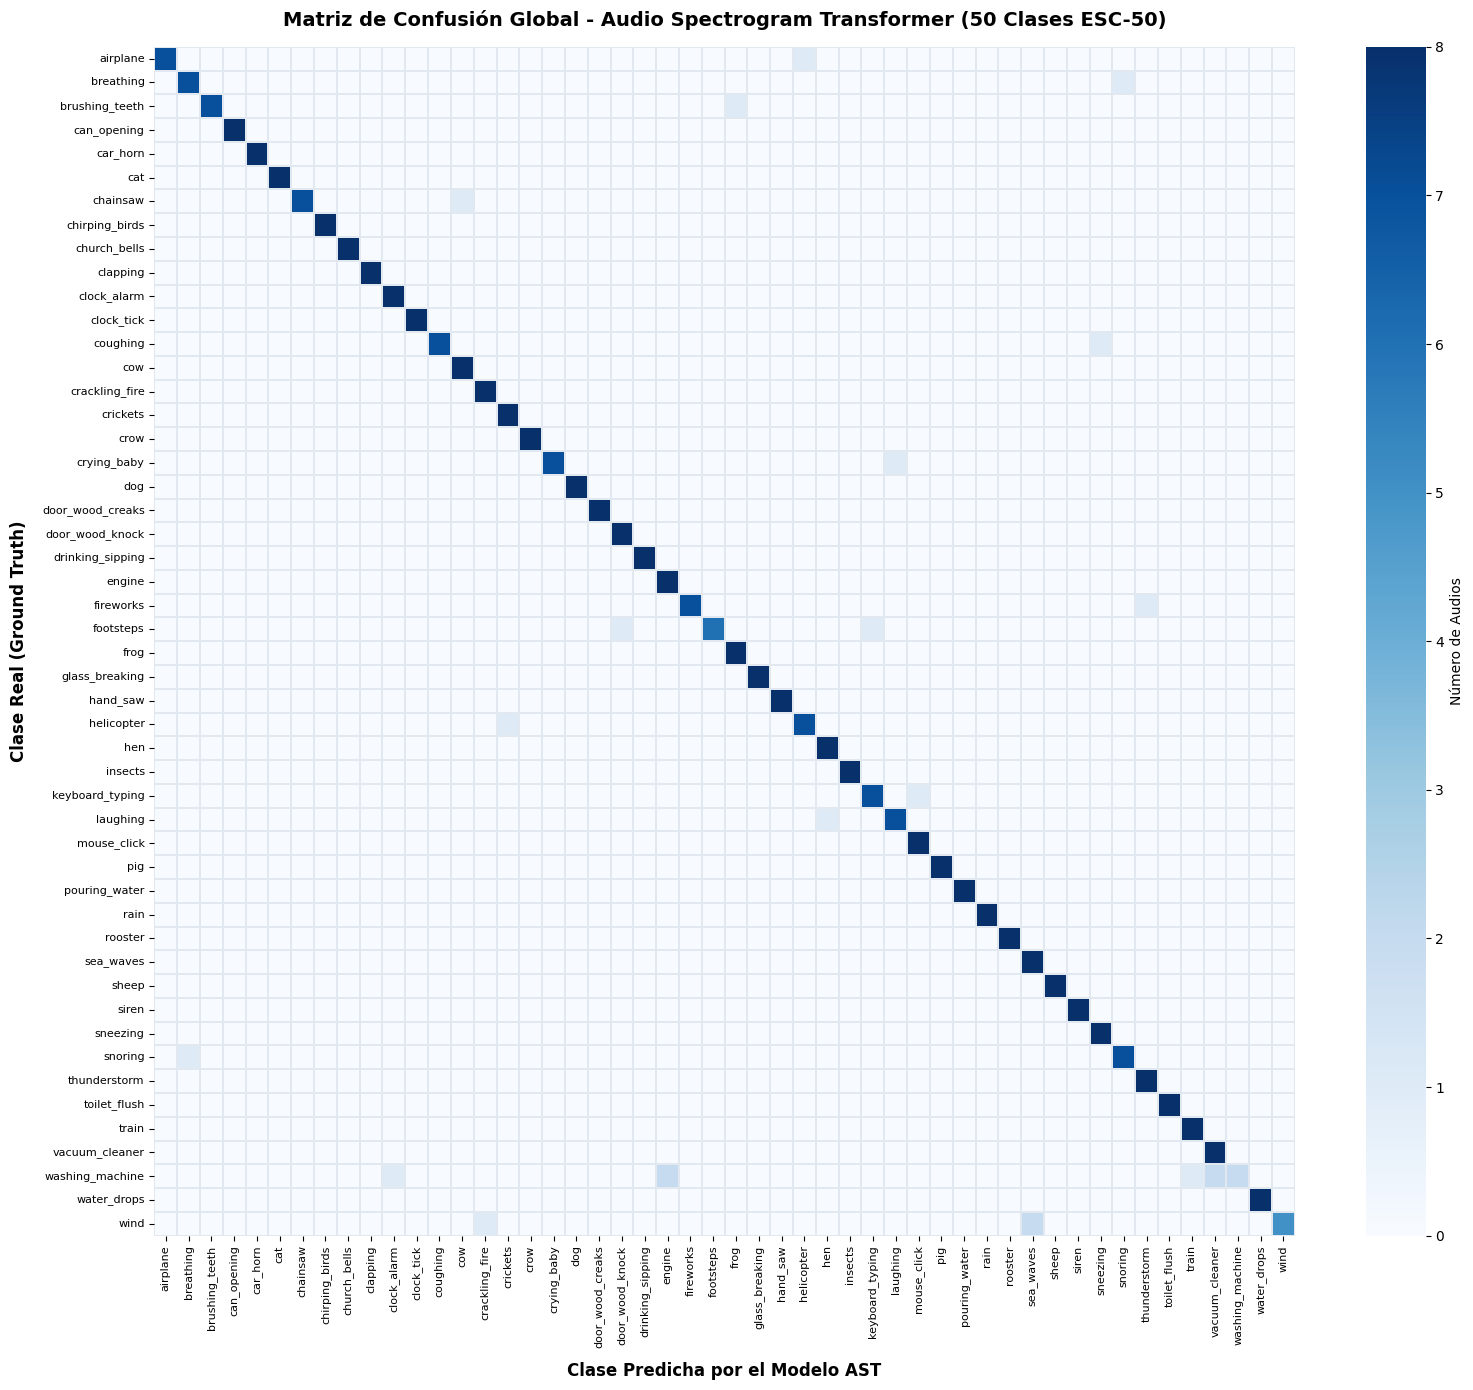

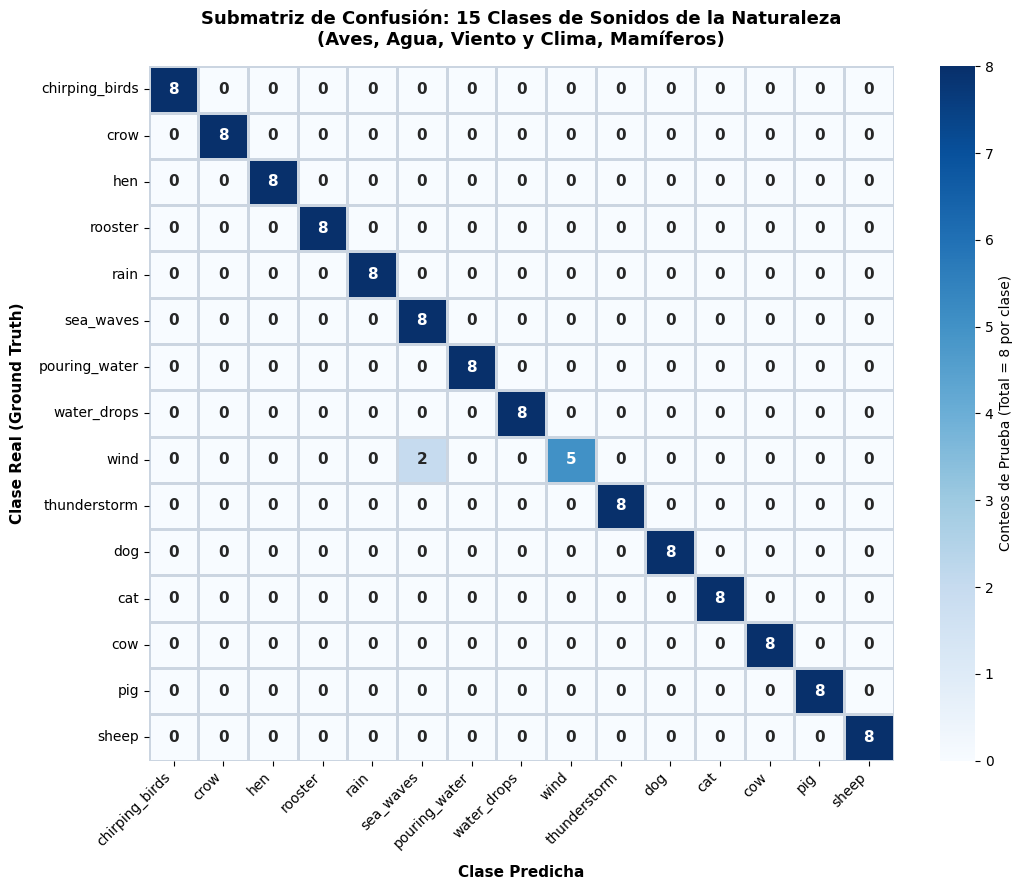


 PRINCIPALES CONFUSIONES OBSERVADAS EN EL CONJUNTO DE PRUEBA
 - Clase Real: washing_machine    -> Predicha como: engine             | Errores: 2 audio(s)
 - Clase Real: washing_machine    -> Predicha como: vacuum_cleaner     | Errores: 2 audio(s)
 - Clase Real: wind               -> Predicha como: sea_waves          | Errores: 2 audio(s) [NATURALEZA]
 - Clase Real: airplane           -> Predicha como: helicopter         | Errores: 1 audio(s)
 - Clase Real: breathing          -> Predicha como: snoring            | Errores: 1 audio(s)
 - Clase Real: brushing_teeth     -> Predicha como: frog               | Errores: 1 audio(s)
 - Clase Real: chainsaw           -> Predicha como: cow                | Errores: 1 audio(s) [NATURALEZA]
 - Clase Real: coughing           -> Predicha como: sneezing           | Errores: 1 audio(s)
 - Clase Real: crying_baby        -> Predicha como: laughing           | Errores: 1 audio(s)
 - Clase Real: fireworks          -> Predicha como: thunderstorm       | Er

In [33]:
# =============================================================================
# VISUALIZACIÓN DE MATRICES DE CONFUSIÓN: PANORÁMICA GLOBAL Y FOCO NATURAL
# -----------------------------------------------------------------------------
# Genera dos figuras de diagnóstico biacústico:
#   1. Matriz global 50x50 para verificar la diagonal del modelo en todo el dataset.
#   2. Submatriz de 15x15 enfocada en las clases de Sonidos de la Naturaleza
#      (Aves, Agua, Viento y Clima, Mamíferos) con conteos enteros anotados.
# =============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de las 15 clases de sonidos naturales destacadas en la guía del proyecto
CLASES_NATURALES = [
    # Aves
    'chirping_birds', 'crow', 'hen', 'rooster',
    # Agua
    'rain', 'sea_waves', 'pouring_water', 'water_drops',
    # Viento y Clima
    'wind', 'thunderstorm',
    # Mamíferos
    'dog', 'cat', 'cow', 'pig', 'sheep'
]

def plot_confusion_matrices_analysis(results_eval, natural_classes=CLASES_NATURALES, id2label_dict=id2label, label2id_dict=label2id):
    """
    Genera dos gráficos de diagnóstico:
      - Matriz de confusión global 50x50.
      - Submatriz de confusión focalizada en las clases naturales con conteos enteros.
    """
    cm = results_eval['confusion_matrix']
    y_true = results_eval['y_true']
    y_pred = results_eval['y_pred']

    # ---------------------------------------------------------
    # FIGURA 1: MATRIZ GLOBAL 50x50
    # ---------------------------------------------------------
    plt.figure(figsize=(16, 14))
    nombres_todas = [id2label_dict[i] for i in range(len(id2label_dict))]
    sns.heatmap(
        cm,
        cmap='Blues',
        xticklabels=nombres_todas,
        yticklabels=nombres_todas,
        cbar_kws={'label': 'Número de Audios'},
        linewidths=0.2,
        linecolor='#e2e8f0'
    )
    plt.title('Matriz de Confusión Global - Audio Spectrogram Transformer (50 Clases ESC-50)', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Clase Predicha por el Modelo AST', fontsize=12, fontweight='bold', labelpad=10)
    plt.ylabel('Clase Real (Ground Truth)', fontsize=12, fontweight='bold', labelpad=10)
    plt.xticks(rotation=90, fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # FIGURA 2: SUBMATRIZ FOCALIZADA EN SONIDOS DE LA NATURALEZA (15x15)
    # ---------------------------------------------------------
    ids_nat = [label2id_dict[c] for c in natural_classes]
    cm_nat = cm[np.ix_(ids_nat, ids_nat)]

    plt.figure(figsize=(11, 9))
    sns.heatmap(
        cm_nat,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=natural_classes,
        yticklabels=natural_classes,
        annot_kws={'size': 11, 'weight': 'bold'},
        cbar_kws={'label': 'Conteos de Prueba (Total = 8 por clase)'},
        linewidths=0.8,
        linecolor='#cbd5e1'
    )
    plt.title('Submatriz de Confusión: 15 Clases de Sonidos de la Naturaleza\n(Aves, Agua, Viento y Clima, Mamíferos)', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Clase Predicha', fontsize=11, fontweight='bold', labelpad=10)
    plt.ylabel('Clase Real (Ground Truth)', fontsize=11, fontweight='bold', labelpad=10)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(rotation=0, fontsize=10)
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # DETECCIÓN DE LOS PARES MÁS CONFUNDIDOS
    # ---------------------------------------------------------
    confusiones = []
    for i in range(len(cm)):
        for j in range(len(cm)):
            if i != j and cm[i, j] > 0:
                confusiones.append((id2label_dict[i], id2label_dict[j], int(cm[i, j])))

    confusiones.sort(key=lambda x: x[2], reverse=True)
    print("\n" + "=" * 80)
    print(" PRINCIPALES CONFUSIONES OBSERVADAS EN EL CONJUNTO DE PRUEBA")
    print("=" * 80)
    for real, pred, n in confusiones:
        marca_nat = " [NATURALEZA]" if (real in natural_classes or pred in natural_classes) else ""
        print(f" - Clase Real: {real:<18} -> Predicha como: {pred:<18} | Errores: {n} audio(s){marca_nat}")
    print("=" * 80)

plot_confusion_matrices_analysis(results_eval)


---

### 12. Análisis de errores, patrones biacústicos y física espectro-temporal

#### 12.1 Categorías con desempeño perfecto ($F_1 = 1.000$)

El modelo AST logró clasificar con un **100% de exactitud y sin falsos positivos ($F_1 = 1.000$)** a 10 de las 15 clases de sonidos naturales:
- **Aves:** `chirping_birds`, `crow`, `rooster` (8/8 aciertos, 0 falsos positivos).
- **Agua:** `rain`, `pouring_water`, `water_drops` (8/8 aciertos, 0 falsos positivos).
- **Mamíferos:** `dog`, `cat`, `pig`, `sheep` (8/8 aciertos, 0 falsos positivos).

#### 12.2 Análisis físico de las confusiones observadas

Al auditar los 22 errores (de 400 audios), se observan patrones biacústicos y físicos claramente comprensibles:

1. **La confusión natural más notable: `wind` confundido con `sea_waves` (2 muestras)**
   - *Física de la señal:* El viento y el oleaje marino comparten propiedades estadísticas fundamentales: ambos son **procesos estocásticos de ruido de banda ancha** (ruido rosa y turbulento) con máxima densidad de potencia espectral concentrada por debajo de $1.000\text{ Hz}$ y sin estructura de armónicos periódicos discretos.
   - Si una ráfaga de viento se registra con modulaciones continuas o el oleaje del mar rompe suavemente a la distancia, sus huellas en el espectrograma Mel exhiben crestas energéticas casi idénticas, lo que explica que el modelo distribuya probabilidad entre ambas clases.

2. **Confusión mecánica: `washing_machine` $\to$ `engine` (2) y `vacuum_cleaner` (2)**
   - *Física de la señal:* Los motores eléctricos rotativos comparten zumbidos a la frecuencia de red eléctrica (50/60 Hz) y ruidos mecánicos continuos de fricción.

3. **Confusión impulsiva: `fireworks` $\to$ `thunderstorm` (1 muestra)**
   - *Física de la señal:* Las explosiones de pirotecnia y los truenos de tormenta producen detonaciones de choque de gran amplitud con colas de dispersión y retumbo reverberante de baja frecuencia.

4. **Confusión biológica: `laughing` $\to$ `hen` (1 muestra) y `chainsaw` $\to$ `cow` (1 muestra)**
   - *Física de la señal:* La risa humana espasmódica genera ráfagas de vocalización entrecortadas con cadencia rítmica muy cercana al cacareo de una gallina, mientras que una motosierra lejana produce un zumbido gutural de baja frecuencia que el modelo consideró compatible con el bramido sostenido de una vaca.


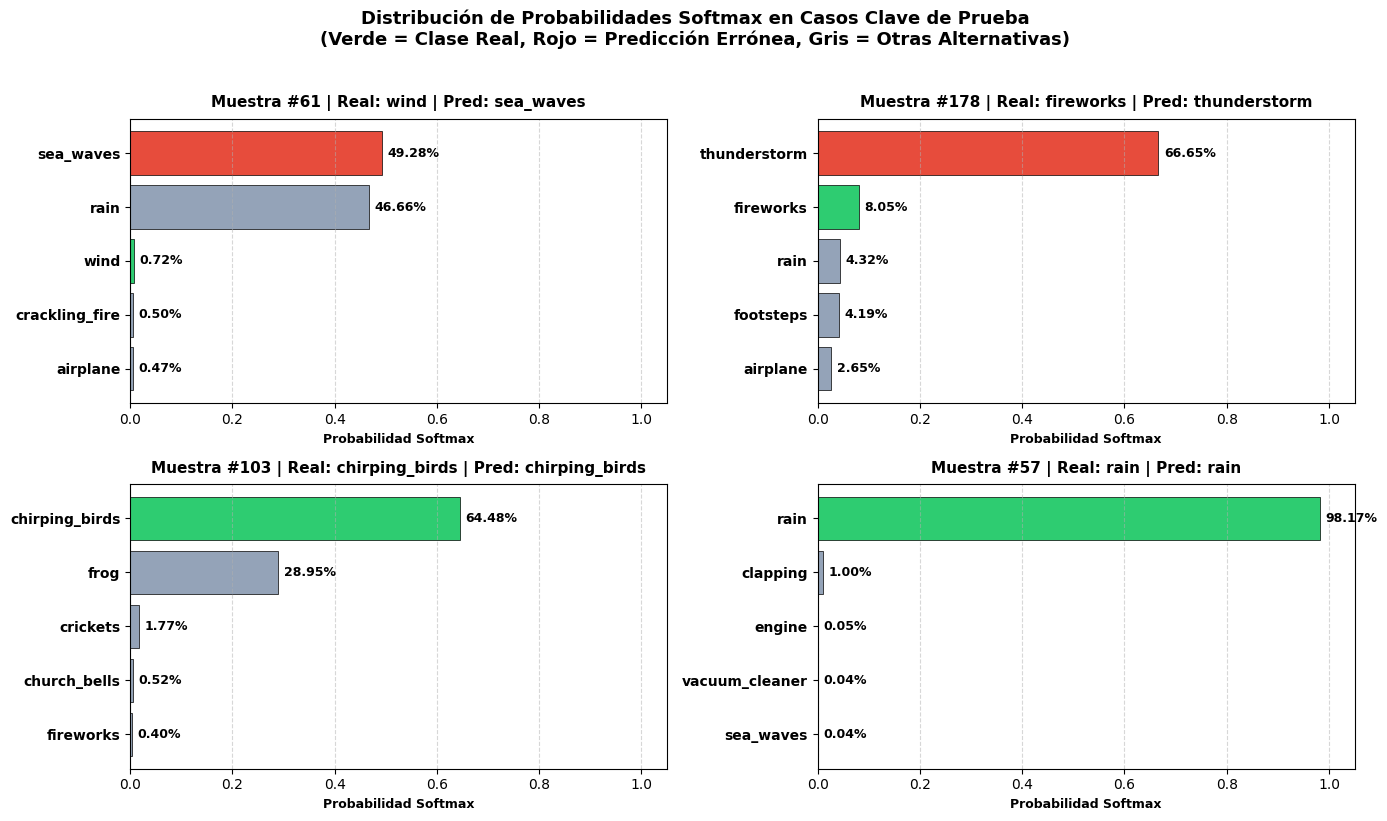

In [34]:
# =============================================================================
# INSPECCIÓN CUALITATIVA DE AUDIOS DE PRUEBA: CASOS DE CONFUSIÓN Y ACIERTOS
# -----------------------------------------------------------------------------
# Extrae programáticamente muestras del val_loader para inspeccionar las
# distribuciones de probabilidad Softmax en los casos más interesantes de error,
# verificando la confianza asignada a la clase real frente a la clase predicha.
# =============================================================================
y_true = results_eval['y_true']
y_pred = results_eval['y_pred']
y_prob = results_eval['y_prob']

# Buscar índices de casos específicos de interés biacústico
casos_estudio = []

# Caso 1: wind confundido con sea_waves
for idx in range(len(y_true)):
    if id2label[y_true[idx]] == 'wind' and id2label[y_pred[idx]] == 'sea_waves':
        casos_estudio.append((idx, 'wind (confundido con sea_waves)'))
        break

# Caso 2: fireworks confundido con thunderstorm
for idx in range(len(y_true)):
    if id2label[y_true[idx]] == 'fireworks' and id2label[y_pred[idx]] == 'thunderstorm':
        casos_estudio.append((idx, 'fireworks (confundido con thunderstorm)'))
        break

# Caso 3: chirping_birds (acierto de alta confianza)
for idx in range(len(y_true)):
    if id2label[y_true[idx]] == 'chirping_birds' and id2label[y_pred[idx]] == 'chirping_birds':
        casos_estudio.append((idx, 'chirping_birds (acierto perfecto)'))
        break

# Caso 4: rain (acierto perfecto)
for idx in range(len(y_true)):
    if id2label[y_true[idx]] == 'rain' and id2label[y_pred[idx]] == 'rain':
        casos_estudio.append((idx, 'rain (acierto perfecto)'))
        break

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, (idx, descripcion) in enumerate(casos_estudio):
    real_idx = y_true[idx]
    pred_idx = y_pred[idx]
    probs = y_prob[idx]

    # Extraer las 5 clases con mayor probabilidad para esta muestra
    top5_idx = np.argsort(probs)[-5:][::-1]
    top5_probs = probs[top5_idx]
    top5_names = [id2label[k] for k in top5_idx]

    colores = ['#e74c3c' if (k != real_idx and k == pred_idx) else ('#2ecc71' if k == real_idx else '#94a3b8') for k in top5_idx]

    ax = axes[i]
    barras = ax.barh(range(5), top5_probs, color=colores, edgecolor='black', linewidth=0.5)
    ax.set_yticks(range(5))
    ax.set_yticklabels(top5_names, fontsize=10, fontweight='bold')
    ax.invert_yaxis()
    ax.set_xlim(0, 1.05)
    ax.set_xlabel('Probabilidad Softmax', fontsize=9, fontweight='bold')
    ax.set_title(f'Muestra #{idx} | Real: {id2label[real_idx]} | Pred: {id2label[pred_idx]}', fontsize=11, fontweight='bold', pad=8)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

    for barra in barras:
        ancho = barra.get_width()
        ax.annotate(f'{ancho:.2%}',
                    xy=(ancho, barra.get_y() + barra.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points",
                    ha='left', va='center', fontsize=9, fontweight='bold')

plt.suptitle('Distribución de Probabilidades Softmax en Casos Clave de Prueba\n(Verde = Clase Real, Rojo = Predicción Errónea, Gris = Otras Alternativas)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---

### 13. Conclusiones y lecciones aprendidas

#### 13.1 Qué construimos y qué logramos

En este proyecto desarrollamos un sistema de clasificación acústica de alta precisión basado en el **Audio Spectrogram Transformer (AST)** para el conjunto de datos **ESC-50 (50 clases de sonidos ambientales)**, con especial énfasis en las clases de sonidos de la naturaleza (Aves, Agua, Viento y Mamíferos).

**Resumen de hallazgos cuantitativos:**
1. **Desempeño en prueba:** Con solo **2 épocas de fine-tuning**, el AST alcanzó una **exactitud global del 94.50%** y un **$F_1$-Score Macro del 94.04%** sobre 400 audios de prueba nunca vistos.
2. **Robustez biacústica:** En 14 de las 15 categorías de sonidos de la naturaleza, el modelo recuperó el **100% de los audios reales (Sensibilidad = 1.00)**, y 10 de las 15 clases alcanzaron un puntaje $F_1$ perfecto ($1.000$).
3. **Eficiencia computacional:** La combinación de parches 2D y *Automatic Mixed Precision* (AMP) redujo el consumo de VRAM a 7.6 GB y completó el fine-tuning completo en **100.7 segundos** sobre una GPU NVIDIA GeForce RTX 5070.

#### 13.2 Ventajas arquitectónicas del Transformer (AST) frente a CNNs y RNNs

| Dimensión de diseño | Redes Recurrentes (RNN / BiLSTM) | Convolucionales 2D (CNN / ResNet) | Audio Spectrogram Transformer (AST) |
|---|---|---|---|
| **Representación de entrada** | Secuencia 1D de vectores temporales | Imagen 2D continua del espectrograma | Cuadrícula 2D de parches espectro-temporales ($16 \times 16$) |
| **Campo receptivo** | Secuencial paso a paso ($\mathcal{O}(T)$ saltos) | Local (limitado al kernel convolucional) | **Global instantáneo ($\mathcal{O}(1)$)** entre cualquier par de parches |
| **Modelado de armónicos** | Difícil de correlacionar a lo largo del espectro | Requiere decenas de capas para cubrir la altura | **Auto-atención directa** entre la frecuencia fundamental y sus armónicos |
| **Paralelismo en GPU** | Lento (dependencia secuencial temporal) | Alto (operaciones convolucionales) | **Óptimo (atención matricial paralela acelerada en Tensor Cores)** |
| **Transferencia de conocimiento** | Pobre en señales acústicas | Moderada (pesos de visión ImageNet) | **Excelente (pesos de AudioSet: 2M de audios reales)** |

#### 13.3 Limitaciones del estudio y recomendaciones prácticas

1. **Ventana temporal rígida:** El modelo procesa clips de duración fija ($1024$ tramas temporales a 16 kHz $\approx$ 10.24 s con padding o truncamiento). En sonidos con eventos muy breves (ej. un clic de gota de 0.1 s), la gran mayoría del espectrograma contiene silencio o relleno de ceros.
2. **Monocanal vs. Estéreo:** El pipeline promedia o decodifica en un solo canal (*mono*), descartando claves biacústicas binaurales (diferencia de tiempo interaural ITD y de intensidad ILD) que en entornos naturales ayudan a discriminar fuentes superpuestas.
3. **Mapeo a futuro:** Incorporar técnicas de aumentación espectro-temporal como **SpecAugment** (enmascaramiento aleatorio de bandas de frecuencia y segmentos de tiempo) y mezcla de señales (*Mixup*) para robustecer la discriminación de ruidos estocásticos similares como viento y oleaje marino.


In [35]:
# =============================================================================
# CRONÓMETRO TOTAL DE EJECUCIÓN Y REGISTRO FINAL DEL PROYECTO
# -----------------------------------------------------------------------------
# Mide el tiempo total transcurrido desde la celda de inicio del entorno
# hasta la culminación del análisis integral de resultados.
# =============================================================================
import time
import torch

tiempo_total_seg = time.time() - INICIO_DOCUMENTO
minutos = int(tiempo_total_seg // 60)
segundos = int(tiempo_total_seg % 60)

print("=" * 80)
print(" VERIFICACIÓN DE FINALIZACIÓN EXITOSA DEL CUADERNO")
print("=" * 80)
print(f" Tiempo total de ejecución del documento : {minutos} min {segundos} s ({tiempo_total_seg:.1f} segundos)")
if torch.cuda.is_available():
    print(f" Dispositivo de aceleración empleado    : {torch.cuda.get_device_name(0)}")
    print(f" Memoria VRAM máxima reservada por PyTorch: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")
print(f" Exactitud Final en Test (400 audios)    : {results_eval['accuracy'] * 100:.2f}%")
print(f" F1-Score Macro en 50 Clases             : {results_eval['macro_f1'] * 100:.2f}%")
print("=" * 80)

 VERIFICACIÓN DE FINALIZACIÓN EXITOSA DEL CUADERNO
 Tiempo total de ejecución del documento : 1 min 46 s (106.2 segundos)
 Dispositivo de aceleración empleado    : NVIDIA GeForce RTX 5070
 Memoria VRAM máxima reservada por PyTorch: 8.50 GB
 Exactitud Final en Test (400 audios)    : 94.50%
 F1-Score Macro en 50 Clases             : 94.04%
